# Рынок стартапов
- Автор: Шалак Лидия
- Дата: 8 октября 2026 г

### Цели и задачи проекта

**Бизнес-задача.** Заказчик – инвестиционная компания, которая планирует вкладывать деньги в стартапы. С позиции начала 2015 года нужно подготовить рекомендацию: **в какую отрасль (сегмент рынка) и в какой тип финансирования вкладываться**.

Для этого используем датасеты `cb_investments.csv` (компании и их финансирование) и `cb_returns.csv` (возвраты средств по годам и типам финансирования): исследуем динамику и структуру финансирования стартапов, долю возврата по типам финансирования и исходы компаний по сегментам.

**План работы**

1. [Описание и загрузка данных](#data)
2. [Предобработка: пропуски, дубликаты, строки без финансирования, типы данных](#preprocessing)
3. [Инжиниринг признаков: группы по срокам финансирования и сегменты рынка](#features)
4. [Типичные и аномальные объёмы финансирования, период исследования](#outliers)
5. [Популярность и объёмы типов финансирования](#types)
6. [Динамика раундов, объёмов и сегментов по годам](#dynamics)
7. [Доля возврата средств по типам финансирования](#returns)
8. [Исходы компаний по сегментам](#outcomes)
9. [Итоговые выводы и рекомендации](#conclusion)

<a id="data"></a>
## Описание данных

Таблица `cb_investments`

Содержит информацию о компаниях и состоявшемся финансировании:

- `name` — название компании;
- `homepage_url` — ссылка на сайт компании;
- `category_list` — категории, в которых работает компания. Указываются через |;
- `market` — основной рынок или отрасль компании;
- `funding_total_usd` — общий объём привлечённых инвестиций в долларах США;
- `status` — текущий статус компании, например, operating, closed и так далее;
- `country_code` — код страны, например USA;
- `state_code` — код штата или региона, например CA;
- `region` — регион, например SF Bay Area;
- `city` — город, в котором расположена компания;
- `funding_rounds` — общее число раундов финансирования;
- `participants` — число участников в раундах финансирования;
- `founded_at` — дата основания компании;
- `founded_month` — месяц основания в формате YYYY-MM;
- `founded_quarter` — квартал основания в формате YYYY-QN;
- `founded_year` — год основания;
- `first_funding_at` — дата первого финансирования;
- `mid_funding_at` — дата среднего по времени раунда финансирования;
- `last_funding_at` — дата последнего финансирования;
- `seed` — сумма инвестиций на посевной стадии;
- `venture` — сумма венчурных инвестиций;
- `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг;
- `undisclosed` — сумма финансирования нераскрытого типа;
- `convertible_note` — сумма инвестиций через конвертируемые займы;
- `debt_financing` — сумма долгового финансирования;
- `angel` — сумма инвестиций от бизнес-ангелов;
- `grant` — сумма полученных грантов;
- `private_equity` — сумма инвестиций в виде прямых (частных) вложений;
- `post_ipo_equity` — сумма финансирования после IPO;
- `post_ipo_debt` — сумма долгового финансирования после IPO;
- `secondary_market` — сумма сделок на вторичном рынке;
- `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг;
- `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

Таблица `cb_returns`

Содержит информацию об объёмах возвратов по годам и типам финансирования в миллионах долларов:

- `year` — год возврата средств;
- `seed` — сумма возвратов от посевных инвестиций;
- `venture` — сумма возвратов от венчурных инвестиций;
- `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу;
- `undisclosed` — сумма возвратов нераскрытого типа;
- `convertible_note` — сумма возвратов через конвертируемые займы;
- `debt_financing` — сумма возвратов от долгового финансирования;
- `angel` — сумма возвратов бизнес-ангелам;
- `grant` — сумма возвратов по грантам;
- `private_equity` — сумма возвратов прямых (частных) вложений;
- `post_ipo_equity` — сумма возвратов от IPO;
- `post_ipo_debt` — сумма возвратов от долгового IPO;
- `secondary_market` — сумма возвратов от сделок на вторичном рынке;
- `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.

In [1]:
# Импортируем библиотеки
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Скрываем предупреждения об устаревших параметрах: в разных версиях библиотек они разные
warnings.filterwarnings('ignore')


def add_bar_labels(ax, fmt='{:.1f}', horizontal=False, labels=None, fontsize=8):
    for i, bar in enumerate(ax.patches):
        if horizontal:
            value = bar.get_width()
            x, y = bar.get_x() + value, bar.get_y() + bar.get_height() / 2
        else:
            value = bar.get_height()
            x, y = bar.get_x() + bar.get_width() / 2, bar.get_y() + value
        text = labels[i] if labels is not None else fmt.format(value)
        if horizontal:
            ax.text(x, y, ' ' + text, ha='left', va='center', fontsize=fontsize)
        else:
            ax.text(x, y, text, ha='center', va='bottom', fontsize=fontsize)

In [2]:
# Выгружаем данные в переменные returns_df и investments_df
# Если файлов нет в папке с тетрадкой, читаем их по ссылке на платформе
import os

DATA_URL = 'https://code.s3.yandex.net/datasets/'


def data_path(file_name):
    return file_name if os.path.exists(file_name) else DATA_URL + file_name


returns_df = pd.read_csv(data_path('cb_returns.csv'), index_col='year')
investments_df = pd.read_csv(data_path('cb_investments.zip'), sep=';', low_memory=False)

display(returns_df.head())
display(investments_df.head())

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0
2003,7.74,233.86,0.0,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.0,0.08,0.0
2004,9.93,555.90,0.0,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.0,0.55,0.0


,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
# Выводим информацию о датафрейме
returns_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15 entries, 2000 to 2014
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   seed                  15 non-null     float64
 1   venture               15 non-null     float64
 2   equity_crowdfunding   15 non-null     float64
 3   undisclosed           15 non-null     float64
 4   convertible_note      15 non-null     float64
 5   debt_financing        15 non-null     float64
 6   angel                 15 non-null     float64
 7   grant                 15 non-null     float64
 8   private_equity        15 non-null     float64
 9   post_ipo_equity       15 non-null     float64
 10  post_ipo_debt         15 non-null     float64
 11  secondary_market      15 non-null     float64
 12  product_crowdfunding  15 non-null     float64
dtypes: float64(13)
memory usage: 1.6 KB


Датасет содержит 15 строк и 14 столбцов – это годовая сводка возвратов по типам финансирования.

13 столбцов float64: суммы возвратов по типам финансирования (seed, venture, equity_crowdfunding, undisclosed, convertible_note, debt_financing, angel, grant, private_equity, post_ipo_equity, post_ipo_debt, secondary_market, product_crowdfunding).

Пропусков нет, типы корректные.

In [4]:
# Выводим информацию о датафрейме
investments_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

Датасет содержит 54 294 строки, 40 столбцов

24 столбца float64: funding_rounds, participants, founded_year и все суммы по типам финансирования (seed – round_H).
16 столбцов object: текстовые поля, даты и funding_total_usd.

4 856 полностью пустых строк. Почти во всех столбцах 49 438 заполненных значений при 54 294 строках. Скорее всего, это пустые строки в файле, которые можно удалить. Ещё у одной компании нет name.

Даты хранятся как строки: founded_at, first_funding_at, mid_funding_at, last_funding_at, их нужно перевести типу даты. founded_month и founded_quarter тоже текстовые. founded_year имеет тип float, удобнее перевести в int64.

У founded_month и founded_quarter на 72 значения меньше, чем у founded_at, возможно, там некорректные даты.

In [5]:
# Выводим количество пропущенных строк в датафрейме
investments_df.isna().sum()

name                     4857
homepage_url             8305
category_list            8817
 market                  8817
 funding_total_usd       4856
status                   6170
country_code            10129
state_code              24133
region                  10129
city                    10972
funding_rounds           4856
participants            23821
founded_at              15740
founded_month           15812
founded_quarter         15812
founded_year            15740
first_funding_at         4856
mid_funding_at          24006
last_funding_at          4856
seed                     4856
venture                  4856
equity_crowdfunding      4856
undisclosed              4856
convertible_note         4856
debt_financing           4856
angel                    4856
grant                    4856
private_equity           4856
post_ipo_equity          4856
post_ipo_debt            4856
secondary_market         4856
product_crowdfunding     4856
round_A                  4856
round_B   

In [6]:
# Подсчитываем процент строк с пропусками
investments_df.isna().sum() / len(investments_df) * 100

name                     8.945740
homepage_url            15.296350
category_list           16.239363
 market                 16.239363
 funding_total_usd       8.943898
status                  11.364055
country_code            18.655837
state_code              44.448742
region                  18.655837
city                    20.208494
funding_rounds           8.943898
participants            43.874093
founded_at              28.990312
founded_month           29.122923
founded_quarter         29.122923
founded_year            28.990312
first_funding_at         8.943898
mid_funding_at          44.214830
last_funding_at          8.943898
seed                     8.943898
venture                  8.943898
equity_crowdfunding      8.943898
undisclosed              8.943898
convertible_note         8.943898
debt_financing           8.943898
angel                    8.943898
grant                    8.943898
private_equity           8.943898
post_ipo_equity          8.943898
post_ipo_debt 

4 856 стоит во всех столбцах с суммами: в funding_total_usd, funding_rounds, first_funding_at и last_funding_at (seed до round_H) – это не пропуски в данных, а полностью пустые строки в конце файла, которые нужно просто удалить. 

У name пропусков на один больше (4 857): у одной компании нет названия.

Пропуски в описании компаний (11–20%): status, homepage_url, category_list, market, country_code, region и city. Строки можно оставить, а пропуски не заполнять или заменить на «unknown».

Пропуски (29–44%): founded_at, founded_year, founded_month, founded_quarter (~29%) – у многих компаний не указана дата основания. Восстановить её не из чего.

state_code (~44%): штат указывают в основном для США, это нормально.
participants (~44%): число инвесторов часто неизвестно.
mid_funding_at (~44%): в основном у компаний с одним раундом, у которых «среднего» раунда просто нет.

**Вывод:**

В датафрейме 4 856 полностью пустых строк (~9%), их удаляем. 

В описательных полях (статус, сайт, категория, страна, город) пропусков немного, строки оставляем. 

Больше всего пропусков в дате основания (~29%), штате, числе участников и дате среднего раунда (~44%). Дату основания, штат и число участников корректно заполнить нельзя, поэтому оставляем их как есть и учитываем при анализе. Пропуски в `mid_funding_at` заполним серединой интервала между `first_funding_at` и `last_funding_at`.

Отдельно: в `funding_total_usd` отсутствие суммы записано прочерком (это строка, а не пропуск), поэтому в таблице пропусков он не виден. Такие строки обработаем после перевода столбца в число.

<a id="preprocessing"></a>
## Предобработка данных

### Обработка пропусков и дубликатов

In [7]:
# Убираем лишние пробелы в названиях столбцов (' market ' -> 'market')
investments_df.columns = investments_df.columns.str.strip()

# Проверяем полные дубликаты до удаления: совпадают ли они с полностью пустыми строками
rows_before = len(investments_df)
print('Полных дубликатов:', investments_df.duplicated().sum())
print('Полностью пустых строк:', investments_df.isna().all(axis=1).sum())

# Удаляем полностью пустые строки и компанию без названия
investments_df = investments_df.dropna(how='all')
investments_df = investments_df.dropna(subset=['name']).reset_index(drop=True)
print('Удалено строк:', rows_before - len(investments_df), '| осталось:', len(investments_df))
print('Полных дубликатов после очистки:', investments_df.duplicated().sum())

# В описательных текстовых столбцах заменяем пропуски на 'unknown'
text_cols = ['homepage_url', 'category_list', 'market', 'status', 'country_code', 'state_code', 'region', 'city']
investments_df[text_cols] = investments_df[text_cols].fillna('unknown')

# participants, founded_at, founded_month(_quarter, _year) оставляем с пропусками: корректно заполнить их нельзя
# mid_funding_at заполним ниже, после перевода дат: серединой интервала между first_funding_at и last_funding_at

# Проверяем, где остались пропуски
left = investments_df.isna().sum()
display(pd.DataFrame({'пропусков': left, 'доля, %': (left / len(investments_df) * 100).round(1)})[left > 0])

Полных дубликатов: 4855
Полностью пустых строк: 4856
Удалено строк: 4857 | осталось: 49437
Полных дубликатов после очистки: 0


,пропусков,"доля, %"
participants,18964,38.4
founded_at,10884,22.0
founded_month,10956,22.2
founded_quarter,10956,22.2
founded_year,10884,22.0
mid_funding_at,19149,38.7


### Проверка дат и числовых значений

In [8]:
# Перевод дат из текстового формата к типу datetime64
dates = ['founded_at', 'first_funding_at', 'mid_funding_at', 'last_funding_at']
investments_df[dates] = investments_df[dates].apply(pd.to_datetime, format='%Y-%m-%d', errors='coerce')

# Самая ранняя и самая поздняя дата в каждом столбце
display(investments_df[dates].agg(['min', 'max']))

# Логические проверки
print('Первое финансирование позже последнего:', (investments_df['first_funding_at'] > investments_df['last_funding_at']).sum())
print('Финансирование раньше основания компании:', (investments_df['first_funding_at'] < investments_df['founded_at']).sum())

,founded_at,first_funding_at,mid_funding_at,last_funding_at
min,1785-01-01,1921-09-01,1960-01-01,1921-09-01
max,2014-12-13,2014-12-31,2013-12-12,2015-01-01


Первое финансирование позже последнего: 0
Финансирование раньше основания компании: 2739


In [9]:
# Заполняем пропуски в mid_funding_at серединой интервала между первым и последним раундом
mid_missing = investments_df['mid_funding_at'].isna()
print('Пропусков в mid_funding_at до заполнения:', mid_missing.sum())

midpoint = investments_df['first_funding_at'] + (investments_df['last_funding_at'] - investments_df['first_funding_at']) / 2
investments_df['mid_funding_at'] = investments_df['mid_funding_at'].fillna(midpoint.dt.normalize())

print('Пропусков в mid_funding_at после заполнения:', investments_df['mid_funding_at'].isna().sum())
display(investments_df.loc[mid_missing, ['first_funding_at', 'mid_funding_at', 'last_funding_at']].head())

Пропусков в mid_funding_at до заполнения: 19149
Пропусков в mid_funding_at после заполнения: 8


,first_funding_at,mid_funding_at,last_funding_at
0,2014-01-06,2014-01-06,2014-01-06
1,2014-05-15,2014-05-15,2014-05-15
4,2014-01-14,2014-01-14,2014-01-14
5,2014-10-23,2014-10-23,2014-10-23
7,2014-01-12,2014-01-12,2014-01-12


In [10]:
# Проверяем корректность числовых значений

# funding_total_usd тип object, хранится как строка с запятыми ('9,00,00,000'): убираем запятые и переводим к числовому типу
investments_df['funding_total_usd'] = pd.to_numeric(investments_df['funding_total_usd'].astype(str).str.replace(',', '', regex=False).str.strip(), errors='coerce')
no_total = investments_df['funding_total_usd'].isna()
print('funding_total_usd имеют значения NaN (прочерк):', no_total.sum())

# Что стоит по типам финансирования у строк с прочерком в общей сумме
type_cols = ['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 'debt_financing',
             'angel', 'grant', 'private_equity', 'post_ipo_equity', 'post_ipo_debt', 'secondary_market',
             'product_crowdfunding', 'round_A', 'round_B', 'round_C', 'round_D', 'round_E', 'round_F',
             'round_G', 'round_H']
print('Сумма по всем типам финансирования у строк с прочерком:', investments_df.loc[no_total, type_cols].sum().sum())
print('Строк с прочерком, где хотя бы один тип > 0:', (investments_df.loc[no_total, type_cols] > 0).any(axis=1).sum())

# Информации о финансировании у этих компаний нет – удаляем строки
rows_with_empty = len(investments_df)
investments_df = investments_df[~no_total].reset_index(drop=True)
print(f'Удалено строк без информации о финансировании: {rows_with_empty - len(investments_df)} | осталось: {len(investments_df)}')

funding_total_usd имеют значения NaN (прочерк): 8531
Сумма по всем типам финансирования у строк с прочерком: 0.0
Строк с прочерком, где хотя бы один тип > 0: 0


Удалено строк без информации о финансировании: 8531 | осталось: 40906


`funding_total_usd` (общая сумма инвестиций)

после удаления строк без информации о финансировании сумма известна у всех 40 906 компаний, у половины компаний сумма не больше 2 млн, у 75% – не больше 10 млн, среднее ~ 16 млн и в 8 раз больше медианы, при максимуме 30 млрд, минимум – 1, нереалистичное значение.

`funding_rounds` (число раундов)

у большинства компаний был 1 раунд (медиана 1, среднее 1,8)

`participants` (число участников раундов)

заполнено у 27 331 компании, обычно 0–2 участника, максимум 32, у четверти компаний 0 участников, хотя раунд у них был, возможно инвесторы скрыты, а не ошибка.

In [11]:
# Основная статистика по ключевым числовым столбцам (числа – в обычной записи, с разделителями тысяч)
display(investments_df[['funding_total_usd', 'funding_rounds', 'participants']]
        .describe().apply(lambda col: col.map('{:,.2f}'.format)))

,funding_total_usd,funding_rounds,participants
count,"40,906.00","40,906.00","27,331.00"
mean,"15,912,914.44",1.82,1.48
std,"168,680,843.70",1.38,2.08
min,1.00,1.00,0.00
25%,"350,000.00",1.00,0.00
50%,"2,000,000.00",1.00,1.00
75%,"10,000,000.00",2.00,2.00
max,"30,079,503,000.00",18.00,32.00


In [12]:
# Оцениваем полноту данных после предобработки
rows_after = len(investments_df)
dropped = rows_before - rows_after
print(f'Строк в исходном датасете: {rows_before}')
print(f'Строк после предобработки: {rows_after}')
print(f'Отброшено строк: {dropped} ({dropped / rows_before:.1%})')

# Столбцы, в которых остались пропуски, и доля заполненных значений в них
na = investments_df.isna().sum()
completeness = pd.DataFrame({'пропусков': na, 'заполнено, %': ((1 - na / rows_after) * 100).round(1)})
display(completeness[na > 0].sort_values('заполнено, %'))

# Заполненность описательных полей: доля значений, отличных от 'unknown'
print((investments_df[text_cols] != 'unknown').mean().mul(100).round(1).sort_values())

Строк в исходном датасете: 54294
Строк после предобработки: 40906
Отброшено строк: 13388 (24.7%)


,пропусков,"заполнено, %"
participants,13575,66.8
founded_month,8772,78.6
founded_quarter,8772,78.6
founded_at,8707,78.7
founded_year,8706,78.7
first_funding_at,2,100.0
mid_funding_at,1,100.0


state_code       62.6
city             89.0
country_code     90.7
region           90.7
category_list    93.9
market           93.9
homepage_url     94.3
status           97.3
dtype: float64


**Полнота данных и предварительный вывод**

- Отброшено 13 388 строк из 54 294 – 24,7% исходного датасета: 4 856 полностью пустых строк, одна компания без названия и 8 531 компания без информации о финансировании (прочерк в `funding_total_usd` и нули по всем типам финансирования). Осталось 40 906 компаний – это все компании, по которым есть данные о финансировании, так что для анализа содержательная информация не потеряна.
- Ключевые для анализа поля заполнены полностью или почти полностью: общая сумма `funding_total_usd`, число раундов и суммы по типам финансирования (100%), даты первого, среднего и последнего раунда (не хватает 1–2 значений), статус (97,3%), рынок (93,9%), страна (90,7%).
- Хуже заполнены дата основания (78,7%), число участников (66,8%) и штат (62,6%). Для задач проекта эти поля второстепенны.

**Предварительный вывод:** данных достаточно, чтобы исследовать динамику и структуру финансирования стартапов. Ограничение: анализ по дате основания и числу участников возможен только на неполной выборке.

<a id="features"></a>
## Инжиниринг признаков

### Группы компаний по срокам финансирования, количеству и объёму инвестиций 

Компаний без группы (нет дат раундов): 2


,количество,"доля компаний, %","сумма инвестиций, млрд $","доля инвестиций, %","медиана на компанию, млн $",среднее число раундов
funding_group,,,,,,
Единичное финансирование,24112,58.9,199.3,30.6,0.9,1.0
Срок финансирования до года,4501,11.0,48.9,7.5,1.7,2.2
Срок финансирования более года,12291,30.0,402.7,61.9,10.0,3.3


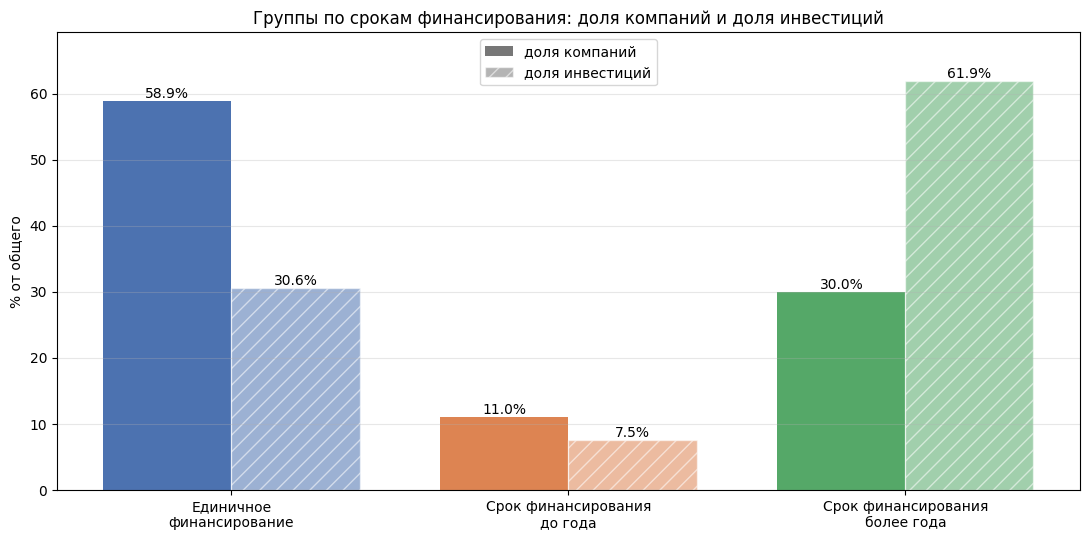

In [13]:
# Делим все компании на три группы по сроку финансирования
funding_df = investments_df.copy()
# Срок финансирования: сколько дней прошло от первого до последнего раунда
funding_df['funding_days'] = (funding_df['last_funding_at'] - funding_df['first_funding_at']).dt.days

group_order = ['Единичное финансирование', 'Срок финансирования до года', 'Срок финансирования более года']
# Единая палитра: каждая группа на всех графиках отображается одним цветом
group_colors = dict(zip(group_order, ['#4C72B0', '#DD8452', '#55A868']))

# Один раунд -> единичное; иначе смотрим на срок между первым и последним раундом
conditions = [funding_df['funding_rounds'] == 1,
              funding_df['funding_days'] <= 365,
              funding_df['funding_days'] > 365]
funding_df['funding_group'] = pd.Categorical(np.select(conditions, group_order, default='нет данных'),
                                             categories=group_order, ordered=True)
print('Компаний без группы (нет дат раундов):', funding_df['funding_group'].isna().sum())

# Считаем показатели по группам
g = funding_df.groupby('funding_group', observed=False)
count = g['name'].count()
total = g['funding_total_usd'].sum()

summary = pd.DataFrame({
    'количество': count,
    'доля компаний, %': count / count.sum() * 100,
    'сумма инвестиций, млрд $': total / 1e9,
    'доля инвестиций, %': total / total.sum() * 100,
    'медиана на компанию, млн $': g['funding_total_usd'].median() / 1e6,
    'среднее число раундов': g['funding_rounds'].mean()})
display(summary.round(1))

# График: для каждой группы два столбца рядом – доля компаний и доля инвестиций.
# Цвет – группа (единая палитра), сплошная заливка – компании, штриховка – инвестиции
colors = [group_colors[name] for name in summary.index]
tick_labels = ['Единичное\nфинансирование', 'Срок финансирования\nдо года', 'Срок финансирования\nболее года']
x = np.arange(len(summary))
width = 0.38

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.bar(x - width / 2, summary['доля компаний, %'], width, color=colors)
ax.bar(x + width / 2, summary['доля инвестиций, %'], width, color=colors, alpha=0.55,
       hatch='//', edgecolor='white')
add_bar_labels(ax, fmt='{:.1f}%', fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(tick_labels)
ax.set(title='Группы по срокам финансирования: доля компаний и доля инвестиций', ylabel='% от общего')
ax.set_ylim(0, summary[['доля компаний, %', 'доля инвестиций, %']].max().max() * 1.12)
ax.grid(axis='y', alpha=0.3)
# Легенда объясняет заливку: сплошная – компании, штриховка – инвестиции
handles = [plt.Rectangle((0, 0), 1, 1, facecolor='#777777'),
           plt.Rectangle((0, 0), 1, 1, facecolor='#777777', alpha=0.55, hatch='//', edgecolor='white')]
ax.legend(handles, ['доля компаний', 'доля инвестиций'], loc='upper center')
plt.tight_layout()
plt.show()

**Выводы**

58,9% компаний получили финансирование 1 раз, но на них приходится только 30,6% всех инвестиций. Медианная сумма у такой компании – 0,9 млн долл.

Компании со сроком финансирования более года – 30,0%, но они собрали 61,9% общего объёма инвестиций: в среднем 3,3 раунда и медиана 10 млн долл на компанию, в 11 раз больше, чем при единичном финансировании.

Группа со сроком финансирования до года самая малочисленная: 11,0% компаний и 7,5% инвестиций, медиана 1,7 млн долл. Несколько раундов за короткое время – редкая ситуация.

Чем дольше компания привлекает деньги, тем больше у неё раундов и тем крупнее суммы. Вероятно, успешные компании продолжают получать инвестиции, а остальные останавливаются после первого раунда.

### Классификация сегментов рынка: массовые, средние и нишевые

Сегмент рынка – значение столбца `market`. Тип сегмента определяем по числу компаний в нём.

Всего сегментов: 394


,компаний
market_original,
Software,4812
Biotechnology,3590
Mobile,2344
E-Commerce,1866
Curated Web,1693
Enterprise Software,1381
Health Care,1185
Clean Technology,1180
Games,1117


Сегментов в каждой категории:
count
массовый     48
средний      57
нишевый     289


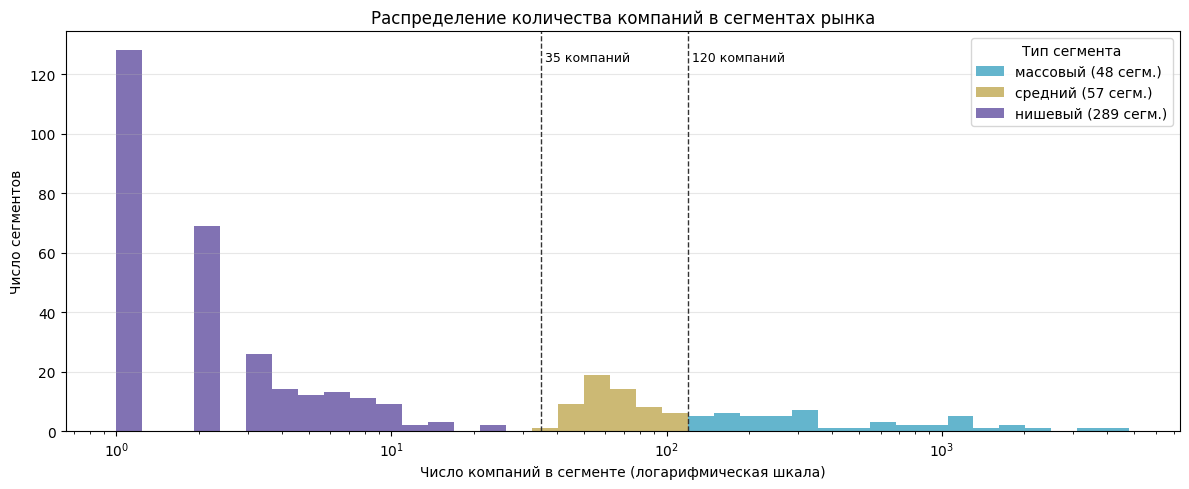

Уникальных значений market после замены: 51


,сегментов,компаний,"доля компаний, %","сумма инвестиций, млрд $","доля инвестиций, %","медиана на компанию, млн $"
market_type,,,,,,
массовый,48,33732,87.8,549.0,87.8,2.3
средний,57,3841,10.0,61.7,9.9,1.5
нишевый,289,830,2.2,14.7,2.3,1.0


Массовые сегменты: Software, Biotechnology, Mobile, E-Commerce, Curated Web, Enterprise Software, Health Care, Clean Technology, Games, Advertising, Hardware + Software, Social Media, Health and Wellness, Education, Finance, Analytics, Manufacturing, Security, Semiconductors, Web Hosting, Consulting, Hospitality, Travel, Fashion, News, Messaging, Search, Real Estate, SaaS, Music, Internet, Technology, Apps, Photography, Sports, Marketplaces, Video, Social Network Media, Automotive, Cloud Computing, Medical, Entertainment, Big Data, Networking, Design, Nonprofits, Public Relations, Startups


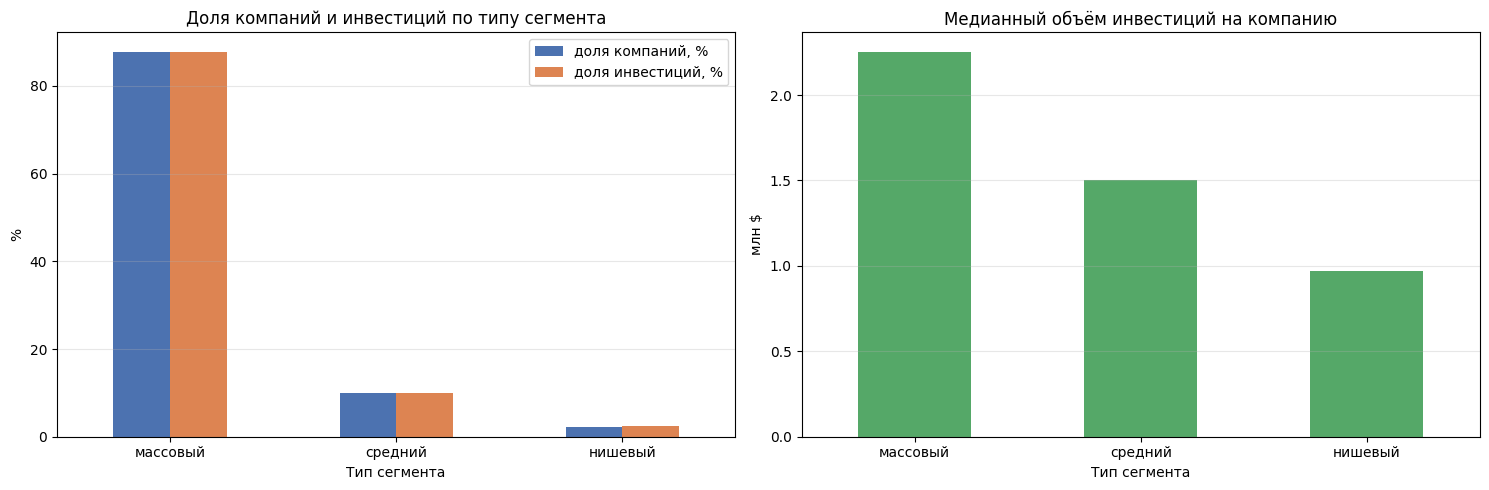

In [14]:
# Убираем лишние пробелы в названиях рынков. Исходные названия сохраняем в market_original,чтобы ячейку можно было запускать повторно
if 'market_original' not in investments_df.columns:
    investments_df['market_original'] = investments_df['market'].str.strip()

# Считаем, как часто встречается каждый сегмент (рынок 'unknown' – это пропуск, его не классифицируем)
market_counts = investments_df.loc[investments_df['market_original'] != 'unknown', 'market_original'].value_counts()
print('Всего сегментов:', len(market_counts))
display(market_counts.head(10).to_frame('компаний'))

# Тип сегмента по числу компаний: до 35 – нишевый, от 35 до 120 включительно – средний, более 120 – массовый
type_order = ['массовый', 'средний', 'нишевый']
type_colors = {'массовый': '#64B5CD', 'средний': '#CCB974', 'нишевый': '#8172B3'}
market_type = pd.cut(market_counts, bins=[0, 34, 120, float('inf')],
                     labels=['нишевый', 'средний', 'массовый']).astype(str)
print('Сегментов в каждой категории:')
print(market_type.value_counts().reindex(type_order).to_string())

# График: распределение числа компаний в сегментах и границы категорий
fig, ax = plt.subplots(figsize=(12, 5))
bins = np.logspace(0, np.log10(market_counts.max()), 40)
ax.hist([market_counts[market_type == t] for t in type_order], bins=bins, stacked=True,
        color=[type_colors[t] for t in type_order],
        label=[f'{t} ({(market_type == t).sum()} сегм.)' for t in type_order])
ax.set_xscale('log')
for border in (35, 120):
    ax.axvline(border, color='#333333', ls='--', lw=1)
    ax.text(border, ax.get_ylim()[1] * 0.95, f' {border} компаний', fontsize=9, va='top')
ax.set(title='Распределение количества компаний в сегментах рынка',
       xlabel='Число компаний в сегменте (логарифмическая шкала)', ylabel='Число сегментов')
ax.legend(title='Тип сегмента')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Добавляем тип сегмента в датафрейм
investments_df['market_type'] = investments_df['market_original'].map(market_type).fillna('unknown')

# В market оставляем только массовые сегменты, остальные заменяем заглушками: mid – средние, niche – нишевые
investments_df['market'] = investments_df['market_original']
investments_df.loc[investments_df['market_type'] == 'средний', 'market'] = 'mid'
investments_df.loc[investments_df['market_type'] == 'нишевый', 'market'] = 'niche'
print('Уникальных значений market после замены:', investments_df['market'].nunique())

# Сравниваем типы сегментов
g = investments_df[investments_df['market_type'] != 'unknown'].groupby('market_type')
count = g['name'].count()
total = g['funding_total_usd'].sum()

seg_summary = pd.DataFrame({
    'сегментов': g['market_original'].nunique(),
    'компаний': count,
    'доля компаний, %': count / count.sum() * 100,
    'сумма инвестиций, млрд $': total / 1e9,
    'доля инвестиций, %': total / total.sum() * 100,
    'медиана на компанию, млн $': g['funding_total_usd'].median() / 1e6,
}).reindex(type_order)
display(seg_summary.round(1))

print('Массовые сегменты:', ', '.join(market_type[market_type == 'массовый'].index))

# Графики
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
seg_summary[['доля компаний, %', 'доля инвестиций, %']].plot(
    kind='bar', ax=axes[0], rot=0, color=['#4C72B0', '#DD8452'],
    title='Доля компаний и инвестиций по типу сегмента')
axes[0].set(xlabel='Тип сегмента', ylabel='%')
seg_summary['медиана на компанию, млн $'].plot(
    kind='bar', ax=axes[1], rot=0, color='#55A868',
    title='Медианный объём инвестиций на компанию')
axes[1].set(xlabel='Тип сегмента', ylabel='млн $')
for ax in axes:
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Выводы:**

В датасете 394 сегмента рынка (без `unknown`). Распределение компаний по ним сильно неравномерное: в половине сегментов не больше 2–3 компаний, а в крупнейшем (Software) – 4 812. Сегменты разделили по числу компаний:

- массовые (более 120 компаний) – 48 сегментов (12% всех), в них 87,8% компаний и 87,8% инвестиций (549 млрд долл), медиана на компанию – 2,3 млн долл;
- средние (от 35 до 120 компаний включительно) – 57 сегментов (14% всех), 10,0% компаний и 9,9% инвестиций, медиана 1,5 млн долл;
- нишевые (менее 35 компаний) – 289 сегментов (73% всех), но лишь 2,2% компаний и 2,3% инвестиций, медиана 1,0 млн долл.

Доля инвестиций у каждого типа примерно равна его доле компаний, но в массовых сегментах типичная компания получает больше: медиана убывает от 2,3 млн долл у массовых до 1,0 млн долл у нишевых. Почти вся активность сосредоточена в полусотне крупных направлений.

Массовые сегменты – это в основном технологии и здоровье. В списке Software, Mobile, E-Commerce, Enterprise Software, Games, Analytics, Security, а также Biotechnology, Health Care, Health and Wellness, Medical и Clean Technology. Именно эти направления формируют основной поток венчурных денег в данных. После удаления компаний без финансирования Medical Devices, Media и Financial Services опустились ниже порога в 120 компаний и стали средними сегментами.

Как учитываем в дальнейшем анализе: в столбце `market` оставлены только массовые сегменты, средние заменены на `mid`, нишевые – на `niche`; исходные названия сохранены в `market_original`, тип сегмента – в `market_type`. Дальше `mid` и `niche` рассматриваем как два общих сегмента наравне с массовыми.

<a id="outliers"></a>
### Типичные и аномальные объёмы финансирования, выбросы и период исследования

**Как оцениваем типичный размер финансирования**

Смотрим на распределение `funding_total_usd` по всем компаниям с известной суммой: гистограмма и диаграмма размаха на логарифмической шкале.

- **Типичные значения** – интервал между Q1 и Q3: в нём лежит половина компаний.
- **Выбивающиеся значения** – выше верхней границы «усов» Q3 + 1,5·IQR.

Здесь граница одна на весь датасет – это общий ориентир. Сами аномальные компании ниже определяем тем же методом, но отдельно в каждом сегменте: типичные суммы в сегментах разные.

,млн $
Q1 (25%),0.35
медиана,2.00
Q3 (75%),10.00
верхняя граница «усов» Q3 + 1.5·IQR,24.48
максимум,30079.50


Типичный интервал (от Q1 до Q3): 0.35–10 млн $
Выше Q3 + 1.5·IQR: 12.8% компаний, 79.0% всех инвестиций
Нижняя граница Q1 - 1.5·IQR: -14.1 млн $ – отрицательная, выбросов снизу нет
Минимальная сумма в данных: 1 $


,name,market,funding_total_usd,funding_rounds
497,Verizon Communications,Mobile,3.007950e+10,5.0
40157,Sberbank,Finance,5.800000e+09,1.0
6120,Clearwire,Internet,5.700000e+09,4.0
1145,Charter Communications,unknown,5.162513e+09,2.0
252,First Data Corporation,mid,3.500000e+09,1.0
39401,COFCO,unknown,3.200000e+09,1.0
8049,sigmacare,Health and Wellness,2.600000e+09,1.0
7014,Facebook,Social Media,2.425700e+09,11.0
11128,Carestream,Biotechnology,2.400000e+09,1.0
11828,Flipkart,mid,2.351140e+09,11.0


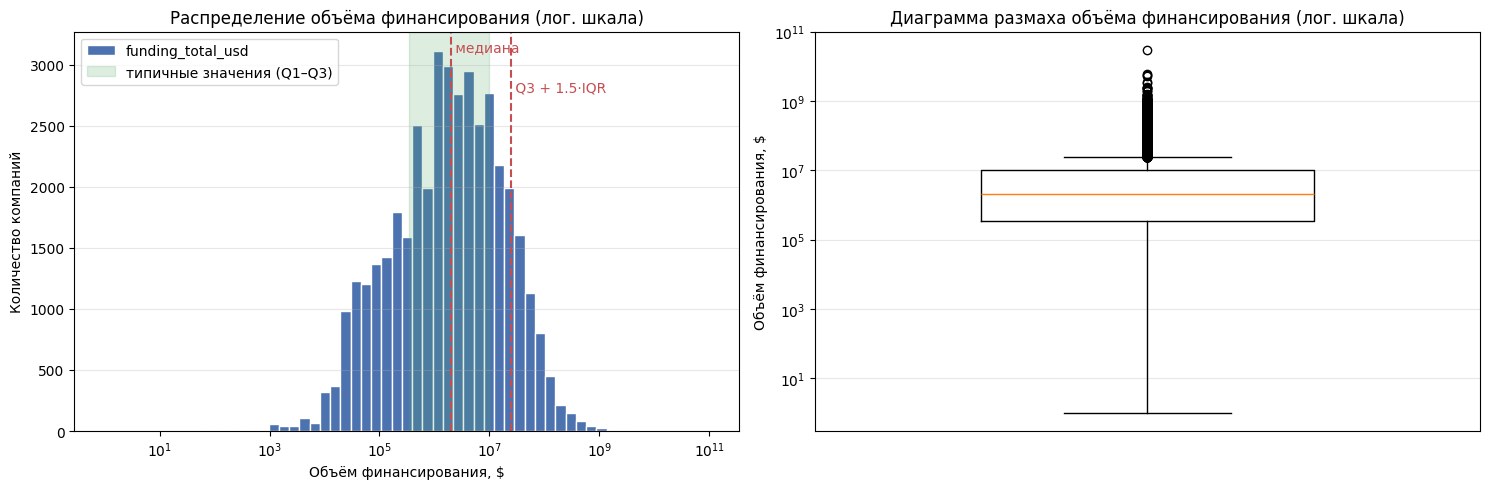

In [15]:
# ---------- 1. Типичные и выбивающиеся значения финансирования ----------
funding = investments_df['funding_total_usd'].dropna()

q1, median, q3 = funding.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
iqr_upper = q3 + 1.5 * iqr          # верхняя граница «усов»
iqr_lower = q1 - 1.5 * iqr          # нижняя граница «усов»

stats = pd.Series({
    'Q1 (25%)': q1,
    'медиана': median,
    'Q3 (75%)': q3,
    'верхняя граница «усов» Q3 + 1.5·IQR': iqr_upper,
    'максимум': funding.max()})
display((stats / 1e6).round(2).to_frame('млн $'))

above_iqr = funding[funding > iqr_upper]
print(f'Типичный интервал (от Q1 до Q3): {q1 / 1e6:.2f}–{q3 / 1e6:.0f} млн $')
print(f'Выше Q3 + 1.5·IQR: {len(above_iqr) / len(funding):.1%} компаний, '
      f'{above_iqr.sum() / funding.sum():.1%} всех инвестиций')
print(f'Нижняя граница Q1 - 1.5·IQR: {iqr_lower / 1e6:.1f} млн $ – отрицательная, выбросов снизу нет')
print(f'Минимальная сумма в данных: {funding.min():,.0f} $')

# Кто попадает в самые большие значения
display(investments_df.nlargest(10, 'funding_total_usd')[['name', 'market', 'funding_total_usd', 'funding_rounds']])

# ---------- 2. Графики распределения ----------
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

funding.plot(kind='hist', bins=np.logspace(0, 11, 60), ax=axes[0], color='#4C72B0', edgecolor='white')
# Типичный интервал Q1–Q3 – заливка, медиана и граница «усов» – линии
axes[0].axvspan(q1, q3, color='#55A868', alpha=0.2, label='типичные значения (Q1–Q3)')
y_top = axes[0].get_ylim()[1]
for value, label, height in [(median, 'медиана', 0.95), (iqr_upper, 'Q3 + 1.5·IQR', 0.85)]:
    axes[0].axvline(value, color='#C44E52', linestyle='--')
    axes[0].text(value, y_top * height, ' ' + label, color='#C44E52')
axes[0].set(xscale='log', title='Распределение объёма финансирования (лог. шкала)',
            xlabel='Объём финансирования, $', ylabel='Количество компаний')
axes[0].legend(loc='upper left')

axes[1].boxplot(funding, widths=0.5)
axes[1].set(yscale='log', title='Диаграмма размаха объёма финансирования (лог. шкала)',
            ylabel='Объём финансирования, $', xticks=[])
axes[0].grid(axis='y', alpha=0.3)
axes[1].grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Типичные значения.** Половина компаний с известной суммой привлекла от 0,35 до 10 млн долл (от Q1 до Q3), медиана – 2 млн долл. Это и есть интервал типичных значений. Распределение сильно скошено вправо: максимум (30 млрд долл у Verizon) больше медианы в 15 000 раз.

**Выбивающиеся значения** – выше 24,5 млн долл (верхняя граница «усов»). Таких компаний 12,8%, но они получают 79% всех денег. На диаграмме размаха за верхним усом стоят не отдельные точки, а сплошная полоса до десятков миллиардов: крупных сумм много, хвост очень длинный.

**В топ-10 в основном не стартапы, а крупные компании и разовые сделки:**

- Verizon, Clearwire, Charter Communications – телеком-операторы; их финансирование, скорее всего, долговое или корпоративное, а не венчурное;
- Sberbank, First Data, COFCO – крупный банк, платёжная корпорация и государственная продовольственная компания Китая; один раунд на миллиарды похож на выпуск акций, выкуп или долговую сделку;
- sigmacare, Carestream – один раунд на 2,4–2,6 млрд долл, что больше похоже на покупку или выделение бизнеса, чем на инвестиции в стартап.

**Снизу выбросов по методу IQR нет:** нижняя граница Q1 − 1,5·IQR отрицательная. При этом минимальная сумма в данных – 1 долл. Суммы в единицы и сотни долларов нереалистичны для инвестиций (вероятно, ошибки ввода или символические гранты), но метод их не выделяет, и в данных они остаются. Учитываем это как ограничение.

**Что делаем дальше.** Заказчика интересует обычный размер финансирования, а аномально крупные суммы его искажают. Но одна граница на весь рынок слишком груба: в разных сегментах типичные суммы различаются в разы. Поэтому ниже считаем границы IQR отдельно в каждом сегменте.

Компаний с рынком 'unknown': 2503; помечено аномальными – 112 по общей границе против 373, если считать 'unknown' отдельным сегментом
Компаний с аномальным финансированием: 4983 (12.2% компаний с известной суммой)
Из них ниже нижней границы: 0


,компаний,аномальных,"доля аномальных, %","Q1, млн $","Q3, млн $","верхняя граница, млн $"
market,,,,,,
Real Estate,279,48,17.2,0.2,5.5,13.5
Entertainment,150,25,16.7,0.1,7.7,19.1
Consulting,349,58,16.6,0.1,5.3,13.1
Search,291,48,16.5,0.3,5.3,12.8
Cloud Computing,152,25,16.4,0.6,10.0,24.1
Photography,204,33,16.2,0.2,4.2,10.4
SaaS,272,44,16.2,0.2,4.1,9.8
Technology,238,38,16.0,0.5,24.2,59.9
Video,188,30,16.0,0.5,7.6,18.4


Объединённые сегменты:


,компаний,аномальных,"доля аномальных, %","Q1, млн $","Q3, млн $","верхняя граница, млн $"
market,,,,,,
mid,3841,556,14.5,0.2,7.8,19.2
niche,830,132,15.9,0.2,5.4,13.2


Доля аномальных по сегментам: минимум 7.0%, медиана 13.2%, максимум 17.2%


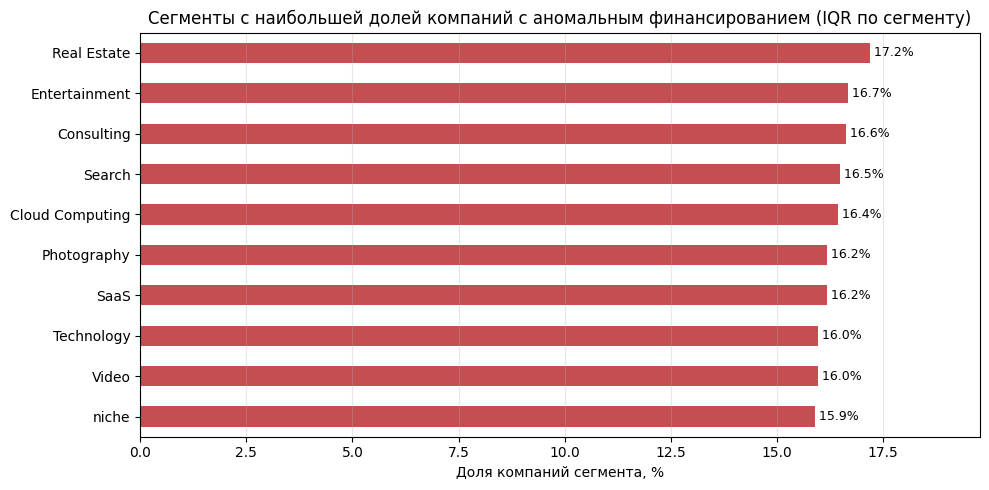

In [16]:
# Помечаем компании с аномальным объёмом финансирования методом IQR отдельно в каждом сегменте.
# В market массовые сегменты идут по отдельности, средние объединены в mid, нишевые – в niche.
# 'unknown' – не рынок, а заглушка: в ней компании из разных отраслей, поэтому своей границы у неё нет,
# для таких компаний берём общую границу по всему датасету (iqr_lower / iqr_upper из ячейки выше)
is_unknown = investments_df['market'] == 'unknown'
seg_funding = investments_df[~is_unknown].groupby('market')['funding_total_usd']
seg_q1 = seg_funding.transform(lambda s: s.quantile(0.25)).reindex(investments_df.index)
seg_q3 = seg_funding.transform(lambda s: s.quantile(0.75)).reindex(investments_df.index)
seg_iqr = seg_q3 - seg_q1
lower_bound = (seg_q1 - 1.5 * seg_iqr).fillna(iqr_lower)
upper_bound = (seg_q3 + 1.5 * seg_iqr).fillna(iqr_upper)
investments_df['funding_outlier'] = ((investments_df['funding_total_usd'] < lower_bound) |
                                     (investments_df['funding_total_usd'] > upper_bound))

# Для сравнения: сколько было бы помечено, если считать 'unknown' отдельным сегментом
all_funding = investments_df.groupby('market')['funding_total_usd']
a_q1 = all_funding.transform(lambda s: s.quantile(0.25))
a_q3 = all_funding.transform(lambda s: s.quantile(0.75))
old_flag = investments_df['funding_total_usd'] > a_q3 + 1.5 * (a_q3 - a_q1)
print(f"Компаний с рынком 'unknown': {is_unknown.sum()}; помечено аномальными – "
      f"{investments_df.loc[is_unknown, 'funding_outlier'].sum()} по общей границе "
      f"против {old_flag[is_unknown].sum()}, если считать 'unknown' отдельным сегментом")

known = investments_df['funding_total_usd'].notna()
print(f"Компаний с аномальным финансированием: {investments_df['funding_outlier'].sum()} "
      f"({investments_df.loc[known, 'funding_outlier'].mean():.1%} компаний с известной суммой)")
print('Из них ниже нижней границы:', (investments_df['funding_total_usd'] < lower_bound).sum())

# Сводка по сегментам (без 'unknown' и компаний с неизвестной суммой)
by_seg = investments_df[known & (investments_df['market'] != 'unknown')].groupby('market')
b_q1 = by_seg['funding_total_usd'].quantile(0.25)
b_q3 = by_seg['funding_total_usd'].quantile(0.75)
outlier_summary = pd.DataFrame({
    'компаний': by_seg.size(),
    'аномальных': by_seg['funding_outlier'].sum(),
    'доля аномальных, %': by_seg['funding_outlier'].mean() * 100,
    'Q1, млн $': b_q1 / 1e6,
    'Q3, млн $': b_q3 / 1e6,
    'верхняя граница, млн $': (b_q3 + 1.5 * (b_q3 - b_q1)) / 1e6,
}).sort_values('доля аномальных, %', ascending=False)

# Топ сегментов с наибольшей долей компаний с аномальным финансированием
top_outliers = outlier_summary.head(10)
display(top_outliers.round(1))
print('Объединённые сегменты:')
display(outlier_summary.loc[['mid', 'niche']].round(1))
print('Доля аномальных по сегментам: минимум {:.1f}%, медиана {:.1f}%, максимум {:.1f}%'.format(
    outlier_summary['доля аномальных, %'].min(), outlier_summary['доля аномальных, %'].median(),
    outlier_summary['доля аномальных, %'].max()))

# График: топ-10 сегментов по доле аномальных компаний
fig, ax = plt.subplots(figsize=(10, 5))
top_outliers['доля аномальных, %'][::-1].plot(kind='barh', ax=ax, color='#C44E52')
add_bar_labels(ax, fmt='{:.1f}%', horizontal=True, fontsize=9)
ax.set(title='Сегменты с наибольшей долей компаний с аномальным финансированием (IQR по сегменту)',
       xlabel='Доля компаний сегмента, %', ylabel='')
ax.set_xlim(0, top_outliers['доля аномальных, %'].max() * 1.15)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

**Выбросы по сегментам (метод IQR)**

- **Типичный размер финансирования** одной компании – от 0,35 до 10 млн долл (от Q1 до Q3, медиана 2 млн долл). По всему датасету выбивающимися можно считать суммы выше ~24,5 млн долл (верхняя граница «усов»).
- **Выбросы помечены в столбце `funding_outlier`**: границы Q1 − 1,5·IQR и Q3 + 1,5·IQR посчитаны отдельно для каждого сегмента (массовые – по отдельности, средние – общая группа `mid`, нишевые – `niche`). `unknown` – не рынок, а заглушка для компаний из разных отраслей, поэтому своей границы у неё нет: для 2 503 таких компаний используем общую границу по датасету. Так аномальными среди них помечены 112 компаний, а если бы считали `unknown` отдельным сегментом – 373.
- Всего аномальными оказались 4 983 компании – 12,2% компаний. Все выбросы – сверху: нижняя граница везде отрицательная, аномально малых сумм метод не выделяет.
- **Топ сегментов по доле аномалий:** Real Estate (17,2%), Entertainment (16,7%), Consulting (16,6%), Search (16,5%), Cloud Computing (16,4%). Разброс между сегментами невелик: от 7,0% до 17,2% при медиане 13,2%.
- **Объединённые сегменты:** в `niche` аномальных 15,9% компаний, в `mid` – 14,5%, оба немного выше медианы.
- **Граница аномалии зависит от сегмента:** в SaaS выбросом считается сумма выше 9,8 млн долл, а в Technology – выше 59,9 млн долл. Поэтому одна и та же сумма может быть типичной в одном сегменте и аномальной в другом.

**Как выбираем период исследования**

Правило отбора одно: год финансирования компании определяем по дате среднего раунда `mid_funding_at` и оставляем годы, в которых после исключения аномалий зафиксировано **50 и более раундов** (расчёт – ниже, при формировании `clean_df`). По этому правилу период исследования – **2000–2014 гг.**: в 1999 году остаётся 45 раундов, в более ранних – ещё меньше. Это совпадает с данными о возвратах `cb_returns`, которые тоже начинаются с 2000 года.

Отдельный шаг – **графики динамики показываем с 2005 года**. В 2000–2004 гг. в каждом году лишь 40–100 компаний, а с 2005 года число записей резко растёт (видно на графике ниже по году первого финансирования и в таблице по году среднего раунда). По таким маленьким выборкам показатели года сильно скачут, и сравнивать их с годами, где тысячи компаний, некорректно.

first_funding_at,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014
компаний,20.0,89.0,136.0,90.0,91.0,137.0,231.0,1433.0,1864.0,2040.0,2312.0,3657.0,4387.0,4964.0,5747.0,7176.0,6477.0
"инвестиции, млрд $",0.6,5.5,4.3,3.0,3.0,4.4,11.3,43.6,55.2,49.7,53.9,80.0,101.8,53.7,44.5,57.8,77.9


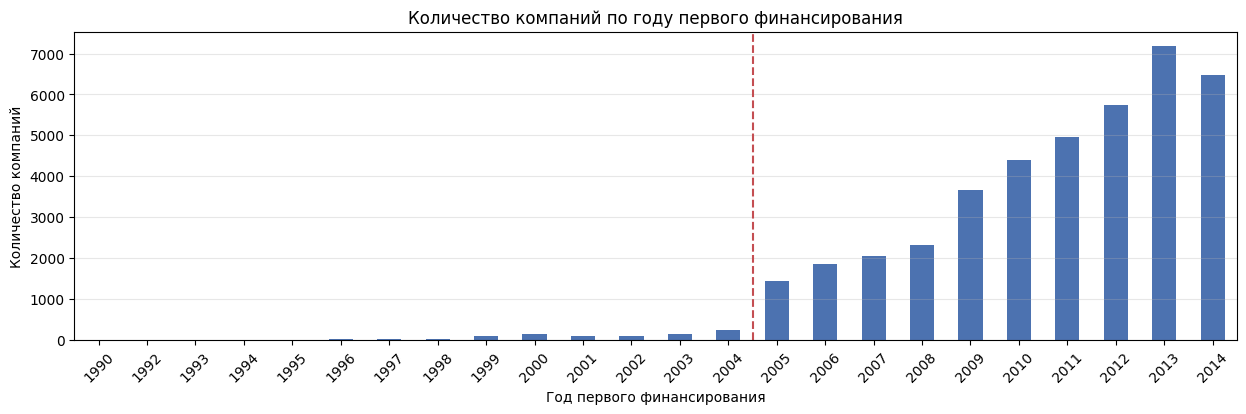

In [17]:
# ---------- 3. Как менялось число компаний в данных по годам, с какого года данных достаточно для анализа ----------
first_year = investments_df['first_funding_at'].dt.year
year_stats = investments_df.groupby(first_year).agg(
    companies=('name', 'count'),
    total_usd=('funding_total_usd', 'sum'))
year_stats.index = year_stats.index.astype(int)   # годы – обычные целые числа (без nullable Int64)

year_table = pd.DataFrame({'компаний': year_stats['companies'],
                           'инвестиции, млрд $': year_stats['total_usd'] / 1e9}).loc[1998:].T
display(year_table.round(1))

counts = year_stats.loc[1990:, 'companies']
ax = counts.plot(kind='bar', figsize=(15, 4), color='#4C72B0', rot=45,
                 title='Количество компаний по году первого финансирования')
ax.set(xlabel='Год первого финансирования', ylabel='Количество компаний')
ax.axvline(counts.index.get_loc(2005) - 0.5, color='#C44E52', linestyle='--')
ax.grid(axis='y', alpha=0.3)
plt.show()

# Итоговый датафрейм clean_df формируется ниже: после проверки данных за 2014 год и исключения аномалий

**Выводы:**

**Аномальные значения**
- По правилу «Q3 + 1,5·IQR» по всему датасету выше ~24,5 млн долл. оказываются 12,8% компаний с 79% всех денег. Заказчика интересует обычный размер финансирования, поэтому аномальные компании исключаем, но границу считаем отдельно в каждом сегменте: аномальными оказались 4 983 компании.
- Среди крупнейших – корпорации и мегасделки (Verizon Communications – 30 млрд долл., Sberbank, Clearwire, Charter Communications, Facebook), которые не отражают типичный рынок стартапов. Нереалистично малые суммы (минимум – 1 долл.) метод IQR не убирает, они остаются в данных.

**Суммы инвестиций** не растут вместе с числом компаний. Пик приходится на 2010 год (101,8 млрд $), а в 2011–2012 годах сумма падает почти вдвое, хотя компаний становится больше. `funding_total_usd` — это все деньги компании за всю её историю, а записываются они в год первого раунда. Компания, начавшая в 2006 году, успела привлечь несколько раундов за восемь лет, а начавшая в 2013 году — только первые один-два. Поэтому ранние когорты стоят дороже не потому, что тогда больше вкладывали, а потому, что у них было больше времени. Для сравнения лет лучше использовать число компаний, медиану или суммы первых раундов, а не накопленный объём.

До 2005 года данных мало: до ~230 компаний в год по году первого финансирования, а в 2005 г. – уже 1 433. Поэтому динамику ниже показываем с 2005 года.

Итоговый датафрейм `clean_df` формируем ниже: исключаем компании с аномальным финансированием (IQR по сегментам) и оставляем годы, в которых было 50 и более раундов.

Самые поздние даты в датасете:
first_funding_at 2014-12-31
mid_funding_at 2014-12-31
last_funding_at 2014-12-31


Компаний по месяцу mid_funding_at:


month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2013,730,520,653,642,633,734,754,775,780,783,762,657
2014,739,600,676,645,600,740,687,559,547,497,306,23


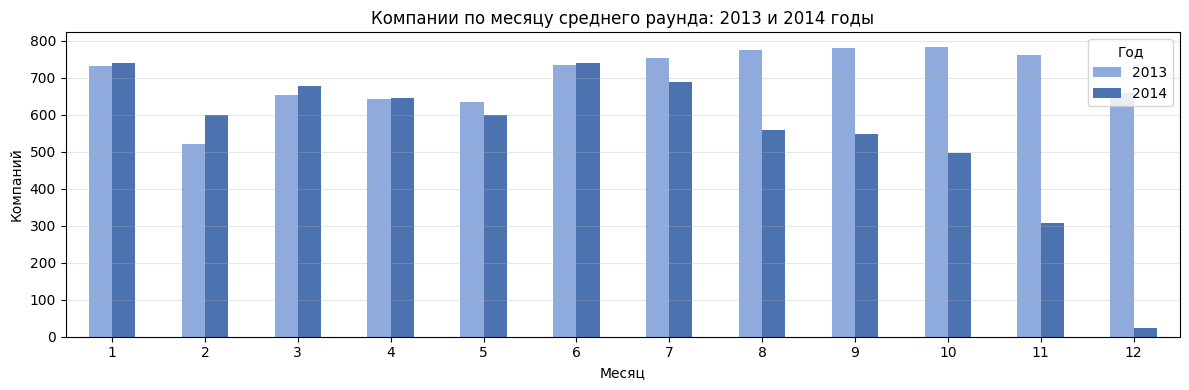

year,1990,1992,1993,1994,1995,1996,1997,1998,1999,2000,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014
компаний,1,4,1,4,4,4,7,13,50,103,...,843,1463,2107,2588,3237,4094,4863,6088,8423,6619
раундов,1,5,1,4,9,11,13,28,118,247,...,1446,2914,4845,6024,7003,8266,9248,11353,14276,7757


In [18]:
# Проверяем, полные ли данные за 2014 год
print('Самые поздние даты в датасете:')
for col in ['first_funding_at', 'mid_funding_at', 'last_funding_at']:
    print(col, investments_df[col].max().date())

# Год финансирования компании – год среднего по времени раунда (mid_funding_at)
mid_year = investments_df['mid_funding_at'].dt.year.rename('year')
mid_month = investments_df['mid_funding_at'].dt.month.rename('month')

# Компании по месяцам: 2013 против 2014
in_13_14 = mid_year.isin([2013, 2014])
monthly_companies = pd.crosstab(mid_month[in_13_14].astype(int), mid_year[in_13_14].astype(int))
print('Компаний по месяцу mid_funding_at:')
display(monthly_companies.T)

fig, ax = plt.subplots(figsize=(12, 4))
monthly_companies.plot(kind='bar', ax=ax, rot=0, color=['#8FAADC', '#4C72B0'])
ax.set(title='Компании по месяцу среднего раунда: 2013 и 2014 годы', xlabel='Месяц', ylabel='Компаний')
ax.legend(title='Год')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Число раундов и компаний по годам (до исключения аномалий)
by_year_raw = investments_df.groupby(mid_year)['funding_rounds'].agg(['count', 'sum'])
by_year_raw.index = by_year_raw.index.astype(int)
by_year_raw.columns = ['компаний', 'раундов']
display(by_year_raw.astype(int).loc[1990:].T)

In [19]:
# 1. Исключаем компании с аномальным финансированием (помечены методом IQR по сегментам)
no_outliers = investments_df[~investments_df['funding_outlier']].copy()

# 2. Год финансирования – год среднего раунда; считаем число раундов в каждом году
no_outliers['year'] = no_outliers['mid_funding_at'].dt.year
rounds_by_year = no_outliers.groupby('year')['funding_rounds'].sum()
rounds_by_year.index = rounds_by_year.index.astype(int)

# 3. Оставляем только годы, в которых зафиксировано 50 или более раундов
good_years = rounds_by_year[rounds_by_year >= 50].index
print('Годы с 50 и более раундами:', ', '.join(str(y) for y in good_years))
print('Годы, которые отбрасываем:', ', '.join(str(y) for y in rounds_by_year.index.difference(good_years)))
display(rounds_by_year.loc[1995:].astype(int).to_frame('раундов').T)

clean_df = no_outliers[no_outliers['year'].isin(good_years)].copy()
clean_df['year'] = clean_df['year'].astype(int)

# Сколько компаний осталось на каждом шаге
steps = pd.Series({
    'исходно': len(investments_df),
    'без аномального финансирования': len(no_outliers),
    'итог: годы с 50+ раундами': len(clean_df)})
display(pd.DataFrame({'компаний': steps,
                      'доля от исходных, %': (steps / steps['исходно'] * 100).round(1)}))

total_clean = clean_df['funding_total_usd'].sum()
print(f"Сумма инвестиций в итоговых данных: {total_clean / 1e9:,.0f} млрд $ "
      f"({total_clean / investments_df['funding_total_usd'].sum():.0%} от исходной)")
print('Компаний без известной суммы в итоговых данных:', clean_df['funding_total_usd'].isna().sum())
print('Период:', clean_df['year'].min(), '–', clean_df['year'].max())
print(clean_df['funding_total_usd'].describe().apply('{:,.0f}'.format).to_string())

Годы с 50 и более раундами: 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014
Годы, которые отбрасываем: 1921, 1960, 1979, 1982, 1983, 1984, 1985, 1987, 1989, 1990, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999


year,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014
раундов,9,8,5,15,45,115,75,106,125,185,958,1881,2844,3679,4661,6175,7605,9743,12927,7200


,компаний,"доля от исходных, %"
исходно,40906,100.0
без аномального финансирования,35923,87.8
итог: годы с 50+ раундами,35847,87.6


Сумма инвестиций в итоговых данных: 164 млрд $ (25% от исходной)
Компаний без известной суммы в итоговых данных: 0
Период: 2000 – 2014
count        35,847
mean      4,580,599
std       8,032,221
min               1
25%         250,000
50%       1,350,000
75%       5,150,000
max      74,989,194


**Границы периода и исключение аномалий**

- **Данные за 2014 год неполные.** Даты в датасете доходят до 31.12.2014, но с августа число компаний падает: 547 в сентябре, 497 в октябре, 306 в ноябре и всего 23 в декабре (в декабре 2013 г. – 657). Последние месяцы года попали в данные лишь частично, поэтому показатели 2014 года занижены и напрямую сравнивать его с предыдущими годами нельзя.
- **Аномалии исключены.** Убрали 4 983 компании с аномальным финансированием (IQR по сегментам), осталось 35 923 (87,8% компаний после предобработки).
- **Период – 2000–2014 гг.** Год финансирования определяем по `mid_funding_at`. 50 и более раундов зафиксировано в каждом году с 2000 по 2014; в 1999 г. – только 45 раундов. Более ранние годы и компании без даты отброшены – это ещё 76 компаний.
- **Итог:** в `clean_df` 35 847 компаний (87,6% от 40 906), у всех известна сумма финансирования. Сумма инвестиций – 164 млрд долл, 25% исходной: аномально крупные сделки давали три четверти всех денег. Медиана на компанию – 1,35 млн долл, максимум – 75 млн долл.

<a id="types"></a>
## Исследовательский анализ

### Популярность и объёмы разных типов финансирования

,компаний,% компаний,"объём, млрд $","доля объёма, %","медиана на компанию, млн $"
venture,19009,53.03,131.01,79.78,3.80
seed,13386,37.34,9.47,5.77,0.30
debt_financing,3291,9.18,8.45,5.14,0.90
angel,2938,8.20,2.50,1.52,0.50
grant,1017,2.84,2.11,1.29,0.32
undisclosed,828,2.31,2.25,1.37,0.81
private_equity,654,1.82,5.06,3.08,4.51
convertible_note,522,1.46,0.57,0.35,0.44
equity_crowdfunding,515,1.44,0.24,0.14,0.08
product_crowdfunding,205,0.57,0.19,0.12,0.30


Доля объёма до исключения аномалий, %:
venture            57.0
private_equity     15.8
debt_financing     14.3
post_ipo_equity     4.6


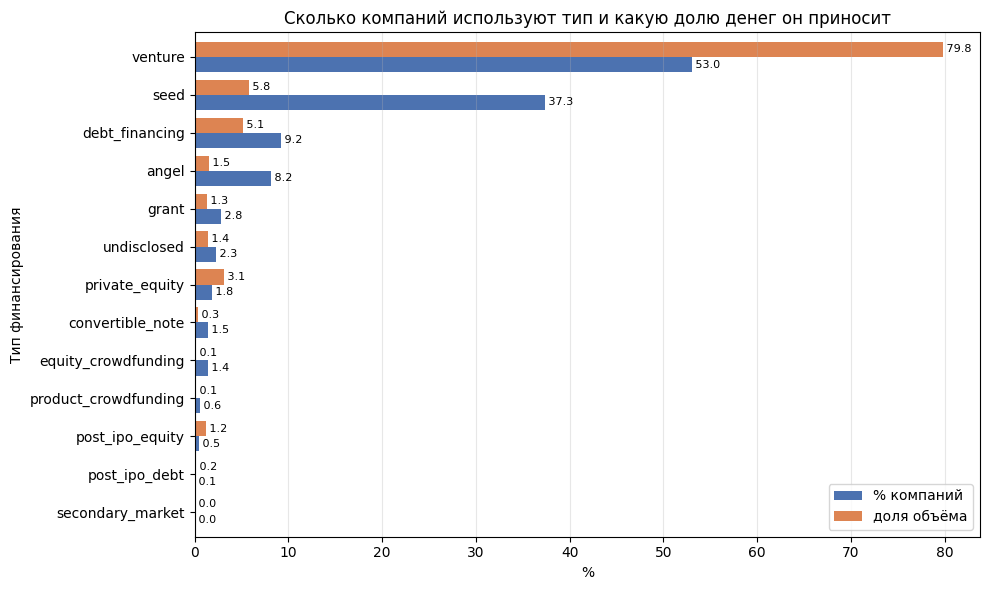

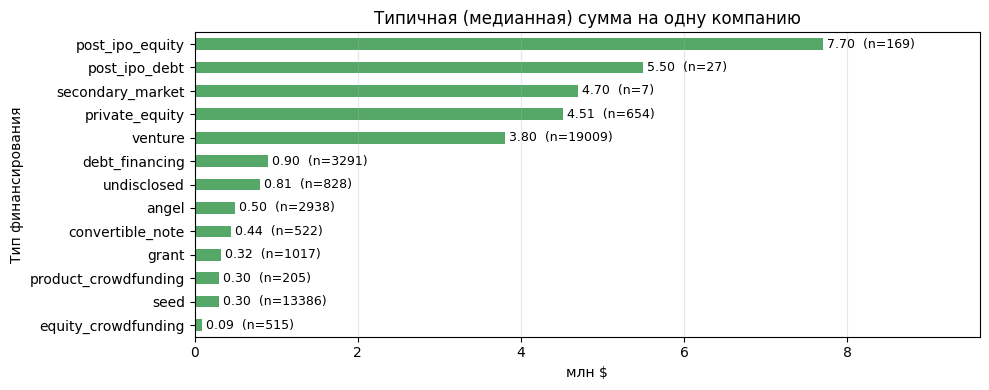

In [20]:
# Типы финансирования – отдельные столбцы с суммами по каждому типу
# (round_A … round_H – стадии венчурного финансирования, они уже входят в venture, поэтому их не берём)
fund_types = ['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note',
              'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity',
              'post_ipo_debt', 'secondary_market', 'product_crowdfunding']

amounts = clean_df[fund_types]
used = amounts > 0          # True, если компания получала финансирование этого типа

types_df = pd.DataFrame({
    'компаний': used.sum(),                                         # популярность
    '% компаний': used.mean() * 100,
    'объём, млрд $': amounts.sum() / 1e9,                           # общий объём
    'доля объёма, %': amounts.sum() / amounts.sum().sum() * 100,
    'медиана на компанию, млн $': amounts[used].median() / 1e6,     # только там, где тип был
}).sort_values('компаний', ascending=False)

display(types_df.round(2))

# Для сравнения: доля объёма по типам до исключения аномалий и фильтра по годам (investments_df)
share_before = investments_df[fund_types].sum() / investments_df[fund_types].sum().sum() * 100
print('Доля объёма до исключения аномалий, %:')
print(share_before.loc[['venture', 'private_equity', 'debt_financing', 'post_ipo_equity']].round(1).to_string())

# График 1. Доля компаний и доля денег по каждому типу рядом
ax = types_df[['% компаний', 'доля объёма, %']][::-1].plot(      # [::-1] – самые популярные сверху
    kind='barh', figsize=(10, 6), width=0.8, color=['#4C72B0', '#DD8452'])

add_bar_labels(ax, horizontal=True)   # подписи значений

ax.set(xlabel='%', ylabel='Тип финансирования',
       title='Сколько компаний используют тип и какую долю денег он приносит')
ax.legend(['% компаний', 'доля объёма'])
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

# График 2. Типичная сумма на компанию, от большей к меньшей
median = types_df['медиана на компанию, млн $'].sort_values()     # по возрастанию – крупнейшие окажутся сверху
ax = median.plot(kind='barh', figsize=(10, 4), color='#55A868')

labels = [f'{m:.2f}  (n={n})' for m, n in zip(median, types_df.loc[median.index, 'компаний'])]
add_bar_labels(ax, horizontal=True, labels=labels, fontsize=9)

ax.set(xlabel='млн $', ylabel='Тип финансирования',
       title='Типичная (медианная) сумма на одну компанию')
ax.set_xlim(0, median.max() * 1.25)                               # место справа для подписей
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

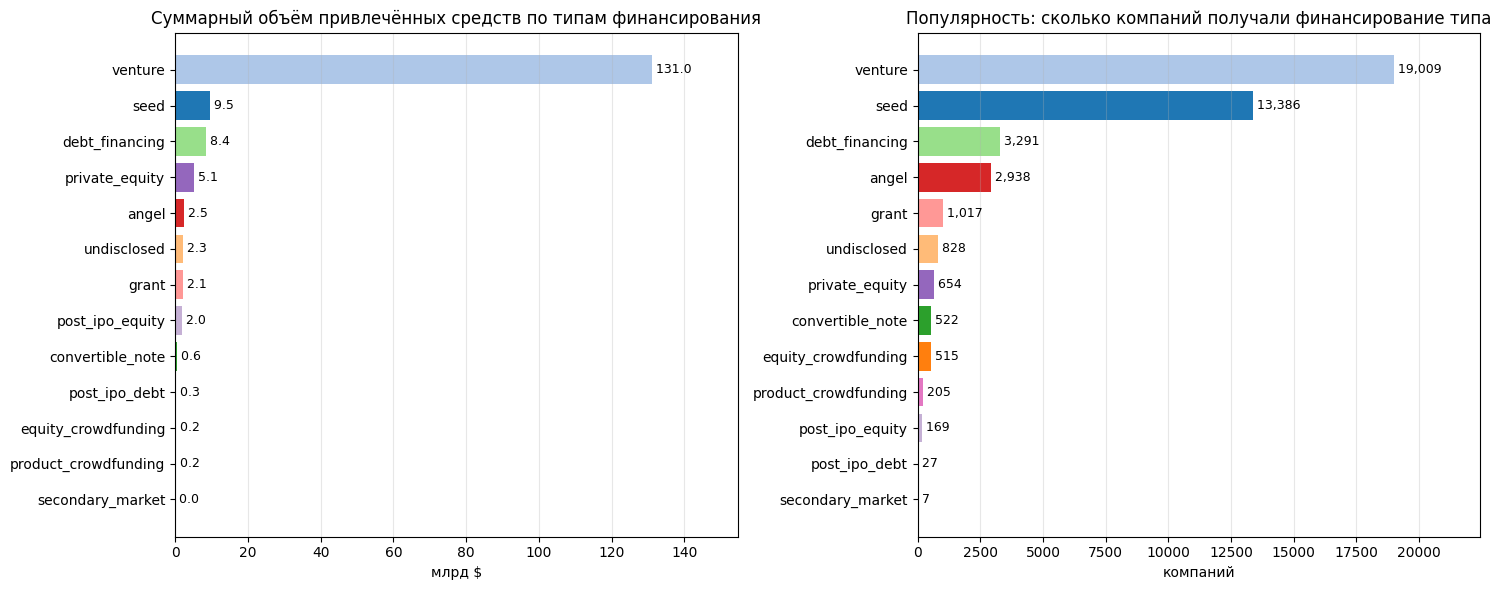

Период в returns_df: 2000 – 2014


,"возвраты, млрд $","доля возвратов, %"
venture,40.58,74.10
debt_financing,4.73,8.65
private_equity,3.59,6.55
seed,2.38,4.35
angel,1.51,2.76
post_ipo_equity,1.10,2.02
undisclosed,0.73,1.33
post_ipo_debt,0.09,0.17
convertible_note,0.03,0.06
secondary_market,0.01,0.01


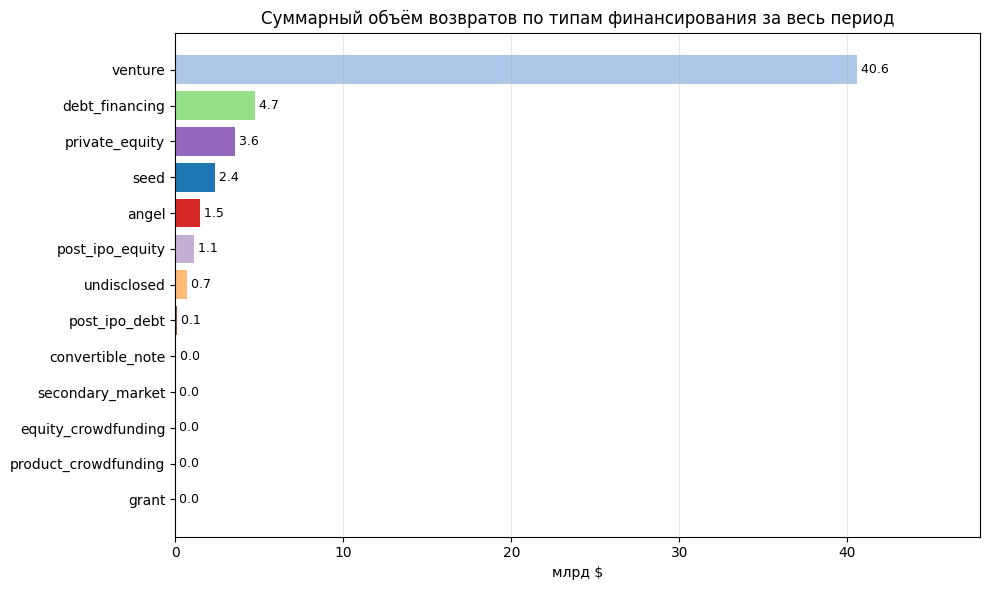

In [21]:
# Единая палитра: каждый тип финансирования на всех графиках одного цвета
fund_colors = dict(zip(fund_types, plt.cm.tab20.colors))

def plot_by_type(series, ax, title, xlabel, fmt):
    s = series.sort_values()                       # крупнейшие окажутся сверху
    ax.barh(s.index, s.values, color=[fund_colors[t] for t in s.index])
    add_bar_labels(ax, fmt=fmt, horizontal=True, fontsize=9)
    ax.set(title=title, xlabel=xlabel)
    ax.set_xlim(0, s.max() * 1.18)
    ax.grid(axis='x', alpha=0.3)

# Графики 1 и 2. Объём привлечённых денег и популярность типов финансирования
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
plot_by_type(types_df['объём, млрд $'], axes[0],
             'Суммарный объём привлечённых средств по типам финансирования', 'млрд $', '{:.1f}')
plot_by_type(types_df['компаний'], axes[1],
             'Популярность: сколько компаний получали финансирование типа', 'компаний', '{:,.0f}')
plt.tight_layout()
plt.show()

# График 3. Суммарные возвраты по типам финансирования за весь период (returns_df, млн $ -> млрд $)
returns_total = returns_df[fund_types].sum() / 1000
print('Период в returns_df:', returns_df.index.min(), '–', returns_df.index.max())
display(pd.DataFrame({'возвраты, млрд $': returns_total,
                      'доля возвратов, %': returns_total / returns_total.sum() * 100})
        .sort_values('возвраты, млрд $', ascending=False).round(2))

fig, ax = plt.subplots(figsize=(10, 6))
plot_by_type(returns_total, ax, 'Суммарный объём возвратов по типам финансирования за весь период', 'млрд $', '{:.1f}')
plt.tight_layout()
plt.show()

**Выводы**

Анализ выполнен по очищенным данным `clean_df` (35 847 компаний, 2000–2014 гг., без компаний с аномальным финансированием).

- **Venture** – главный тип по обоим показателям: его получали 53% компаний, на него приходится 80% всего объёма (131 млрд долл), медиана – 3,8 млн долл на компанию.
- **Seed** – второй по популярности (37% компаний), но чеки небольшие: медиана 0,3 млн долл, всего 5,8% объёма. Посевные раунды массовые, но дешёвые.
- **Debt financing и angel** (9% и 8% компаний) – заметны по числу компаний, дают 5,1% и 1,5% объёма.
- **Private equity** – редкий (1,8% компаний), но крупный: медиана 4,5 млн долл и 3,1% объёма. До исключения аномалий его доля в объёме была 15,8% (см. строку для сравнения под таблицей): крупные сделки private equity ушли вместе с аномальными компаниями.
- **Post-IPO equity и post-IPO debt** – единичные сделки (менее 0,5% компаний) с самыми крупными медианными суммами (5,5–7,7 млн долл).
- **Grant, undisclosed, convertible note, краудфандинг, secondary market** – редкие типы: каждый используют менее 3% компаний, в сумме у них ~3% объёма; у equity-краудфандинга самые маленькие суммы (медиана 0,08 млн долл).

Популярность и объём сильно различаются. Входные инструменты ранних стадий (seed, angel) дают небольшие суммы, а основной поток денег идёт через venture.

**Сравнение популярности и объёма.** Часто используются (больше 5% компаний), но дают мало денег: seed (37% компаний и 5,8% объёма) и angel (8% и 1,5%). Редкие, но крупные: private equity (1,8% компаний и 3,1% объёма) и post-IPO equity (0,5% и 1,2%) – их доля в деньгах в 2–3 раза выше доли по числу компаний. Venture лидирует по обоим показателям.

**Возвраты за весь период (2000–2014, `returns_df`).** Всего 54,8 млрд долл: venture – 40,6 млрд (74%), debt financing – 4,7 млрд (8,7%), private equity – 3,6 млрд (6,6%), seed – 2,4 млрд (4,4%), angel – 1,5 млрд (2,8%). Структура возвратов повторяет структуру инвестиций: основную часть денег инвесторам возвращает venture. Краудфандинг, secondary market и convertible note почти ничего не возвращают, гранты – ноль.

<a id="dynamics"></a>
### Динамика раундов и объёмов инвестиций по годам, изменения в массовых сегментах

Год компании – год её среднего раунда (`mid_funding_at`), данные – `clean_df`; динамику показываем с 2005 г. Сначала смотрим, как менялись число компаний, раундов и объём денег, затем – как перераспределялась доля между сегментами.

year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014
компаний,66.00,41.00,52.00,63.0,100.00,705.0,1180.00,1602.00,1996.0,2651.0,3495.00,4327.00,5556.0,7856.00,6157.0
раундов,115.00,75.00,106.00,125.0,185.00,958.0,1881.00,2844.00,3679.0,4661.0,6175.00,7605.00,9743.0,12927.00,7200.0
"типичный раунд (медиана), млн $",2.26,2.36,3.68,1.5,3.03,4.5,3.95,2.88,2.2,1.5,1.27,0.88,0.7,0.57,0.6


Максимальный типичный размер раунда: 2005 г. – 4.50 млн $
2014 к 2013: раундов -44%, типичный раунд +5%


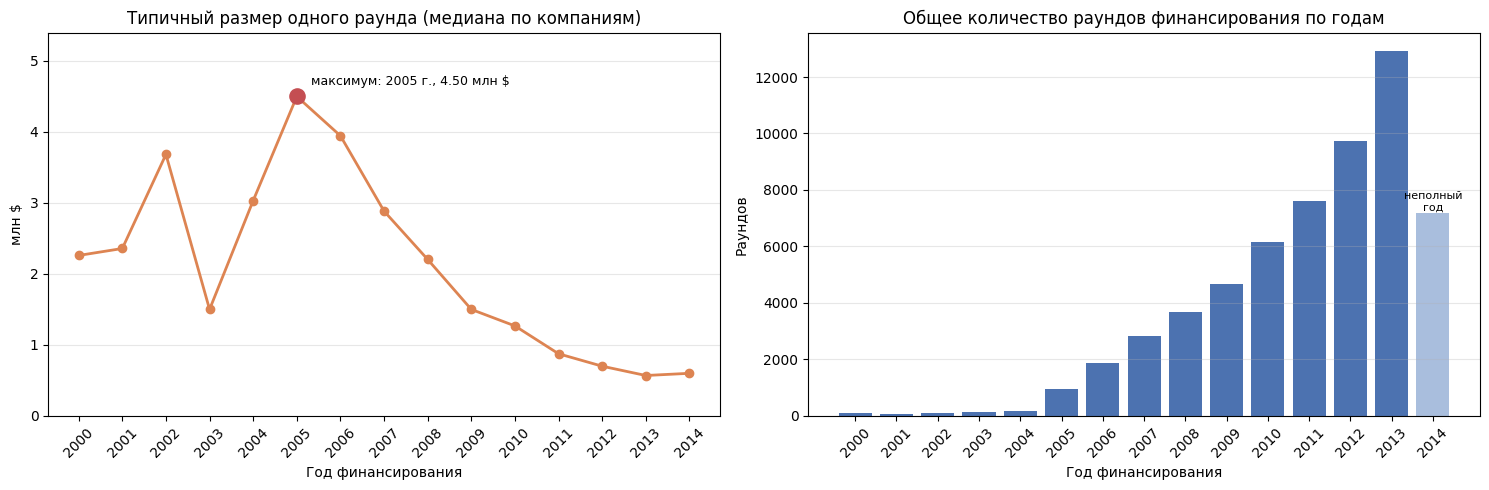

In [22]:
# Средний объём одного раунда для каждой компании: общая сумма / число раундов
clean_df['avg_round_usd'] = clean_df['funding_total_usd'] / clean_df['funding_rounds']

# По годам (год – по mid_funding_at): типичный размер раунда (медиана) и общее число раундов
round_dyn = clean_df.groupby('year').agg(
    companies=('name', 'count'),
    rounds=('funding_rounds', 'sum'),
    median_round=('avg_round_usd', 'median'))
round_dyn['rounds'] = round_dyn['rounds'].astype(int)
round_dyn['median_round'] = round_dyn['median_round'] / 1e6
display(round_dyn.rename(columns={'companies': 'компаний', 'rounds': 'раундов',
                                  'median_round': 'типичный раунд (медиана), млн $'}).T.round(2))

best_year = round_dyn['median_round'].idxmax()
print(f"Максимальный типичный размер раунда: {best_year} г. – {round_dyn.loc[best_year, 'median_round']:.2f} млн $")
print(f"2014 к 2013: раундов {round_dyn.loc[2014, 'rounds'] / round_dyn.loc[2013, 'rounds'] - 1:+.0%}, "
      f"типичный раунд {round_dyn.loc[2014, 'median_round'] / round_dyn.loc[2013, 'median_round'] - 1:+.0%}")

years = round_dyn.index
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# График 1. Типичный размер одного раунда
axes[0].plot(years, round_dyn['median_round'], marker='o', lw=2, color='#DD8452')
axes[0].scatter([best_year], [round_dyn.loc[best_year, 'median_round']], s=120, color='#C44E52', zorder=3)
axes[0].annotate(f"максимум: {best_year} г., {round_dyn.loc[best_year, 'median_round']:.2f} млн $",
                 (best_year, round_dyn.loc[best_year, 'median_round']),
                 textcoords='offset points', xytext=(10, 8), fontsize=9)
axes[0].set(title='Типичный размер одного раунда (медиана по компаниям)',
            xlabel='Год финансирования', ylabel='млн $')
axes[0].set_ylim(0, round_dyn['median_round'].max() * 1.2)

# График 2. Общее число раундов за год (2014 г. – неполные данные, показан светлее)
bar_colors = ['#A9BEDD' if y == 2014 else '#4C72B0' for y in years]
axes[1].bar(years, round_dyn['rounds'], color=bar_colors)
axes[1].text(2014, round_dyn.loc[2014, 'rounds'], 'неполный\nгод', ha='center', va='bottom', fontsize=8)
axes[1].set(title='Общее количество раундов финансирования по годам',
            xlabel='Год финансирования', ylabel='Раундов')

for ax in axes:
    ax.set_xticks(list(years))
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Типичный размер раунда и число раундов по годам**

Для каждой компании посчитан средний объём одного раунда (`funding_total_usd / funding_rounds`, столбец `avg_round_usd`). Типичный размер раунда за год – медиана этого показателя по компаниям; год определяем по `mid_funding_at`.

- **Максимальный типичный размер раунда – в 2005 году: 4,5 млн долл.** После этого он снижается каждый год: 2,2 млн в 2008 г., 1,27 млн в 2010 г. и 0,57 млн в 2013 г. – в 8 раз меньше пика.
- **До 2005 года** показатель скачет от 1,5 до 3,7 млн долл: в эти годы в данных всего 41–100 компаний в год, оценки ненадёжны.
- **Активность рынка росла каждый год с 2005 по 2013:** число раундов увеличилось с 1,0 до 12,9 тыс. Раундов становилось больше, а каждый из них – меньше: рынок рос за счёт массовых небольших раундов ранних стадий.
- **2014 год:** число раундов упало на 44% (7,2 тыс. против 12,9 тыс. в 2013 г.), а типичный размер раунда почти не изменился – 0,60 млн долл против 0,57 млн (+5%), то есть многолетнее снижение остановилось. Падение числа раундов нельзя считать спадом рынка: данные за 2014 год неполные, последние месяцы почти не заполнены.

year,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014
компаний,705.00,1180.00,1602.00,1996.00,2651.00,3495.00,4327.00,5556.00,7856.00,6157.00
раундов,958.00,1881.00,2844.00,3679.00,4661.00,6175.00,7605.00,9743.00,12927.00,7200.00
"объём, млрд $",5.13,9.61,13.01,15.74,17.37,19.85,19.81,20.71,24.86,15.57
раундов на компанию,1.36,1.59,1.78,1.84,1.76,1.77,1.76,1.75,1.65,1.17
"средний раунд, млн $",5.35,5.11,4.57,4.28,3.73,3.21,2.61,2.13,1.92,2.16
"медиана на компанию, млн $",5.33,5.16,4.18,3.65,2.20,2.00,1.34,1.00,0.90,0.70


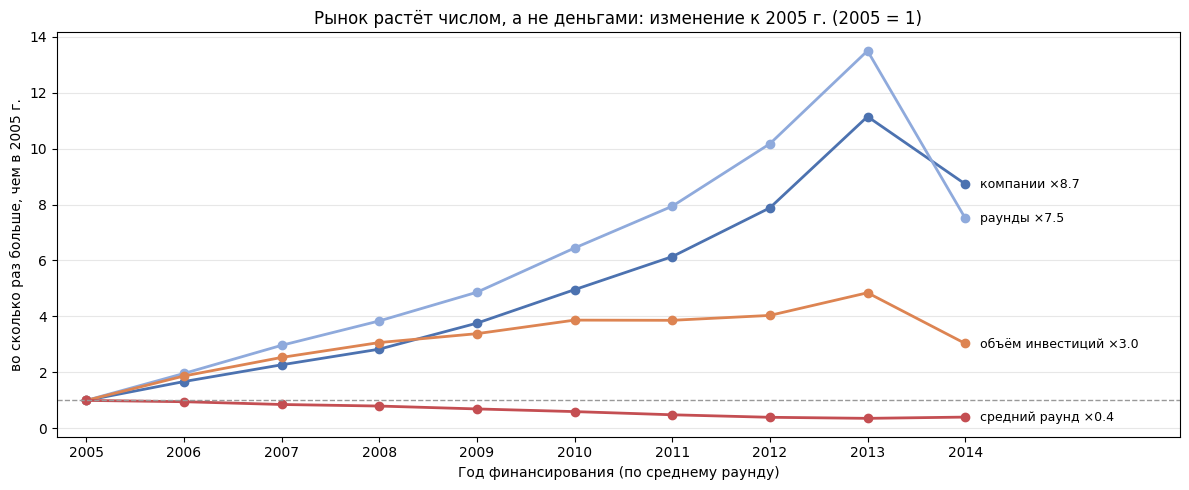

In [23]:
# Год – год среднего раунда (mid_funding_at): столбец year создан при формировании clean_df.
# Динамику показываем с 2005 г.: в более ранние годы компаний слишком мало

g = clean_df[clean_df['year'] >= 2005].groupby('year')
dyn = pd.DataFrame({
    'компаний': g['name'].count(),
    'раундов': g['funding_rounds'].sum(),
    'объём, млрд $': g['funding_total_usd'].sum() / 1e9})
dyn['раундов на компанию'] = dyn['раундов'] / dyn['компаний']
dyn['средний раунд, млн $'] = dyn['объём, млрд $'] * 1000 / dyn['раундов']
dyn['медиана на компанию, млн $'] = g['funding_total_usd'].median() / 1e6
display(dyn.T.round(2))

# График: всё в одной шкале – «во сколько раз изменилось по сравнению с 2005 г.»
cols = ['компаний', 'раундов', 'объём, млрд $', 'средний раунд, млн $']
index = dyn[cols] / dyn[cols].iloc[0]
names = {'компаний': 'компании', 'раундов': 'раунды',
         'объём, млрд $': 'объём инвестиций', 'средний раунд, млн $': 'средний раунд'}
line_colors = ['#4C72B0', '#8FAADC', '#DD8452', '#C44E52']

fig, ax = plt.subplots(figsize=(12, 5))
years = dyn.index
for col, color in zip(index.columns, line_colors):
    ax.plot(years, index[col], marker='o', lw=2, color=color, label=names[col])
    last = index[col].iloc[-1]
    ax.text(years[-1] + 0.15, last, '{} ×{:.1f}'.format(names[col], last), va='center', fontsize=9)
ax.axhline(1, color='#999999', lw=1, ls='--')
ax.set_xticks(list(years))
ax.set_xlim(years[0] - 0.3, years[-1] + 2.2)                 # место справа для подписей
ax.set(title='Рынок растёт числом, а не деньгами: изменение к 2005 г. (2005 = 1)',
       xlabel='Год финансирования (по среднему раунду)', ylabel='во сколько раз больше, чем в 2005 г.')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014
"доля компаний, %",72.7,56.1,88.5,82.5,80.0,92.6,91.9,92.7,91.0,87.5,88.1,86.9,83.6,81.7,64.9
"доля инвестиций, %",78.7,72.3,85.2,88.8,84.2,93.4,93.6,95.3,95.3,93.0,93.2,93.4,91.0,89.7,74.1


,"компании 2005–07, %","компании 2011–13, %","инвестиции 2005–07, %","инвестиции 2011–13, %","изм. доли компаний, п.п.","изм. доли инвестиций, п.п."
market,,,,,,
mid,4.8,9.0,3.9,6.0,4.2,2.1
E-Commerce,1.6,5.5,0.7,3.2,3.9,2.5
Biotechnology,7.5,9.8,10.6,23.9,2.3,13.3
Mobile,4.6,6.7,3.7,4.4,2.1,0.7
Health and Wellness,0.5,2.5,0.4,2.1,2.0,1.6
Education,0.6,2.4,0.1,1.1,1.8,1.0
Health Care,2.2,3.4,4.9,9.1,1.3,4.1
Social Media,1.8,3.1,0.5,0.8,1.2,0.3
Clean Technology,1.2,2.3,2.5,5.8,1.1,3.3


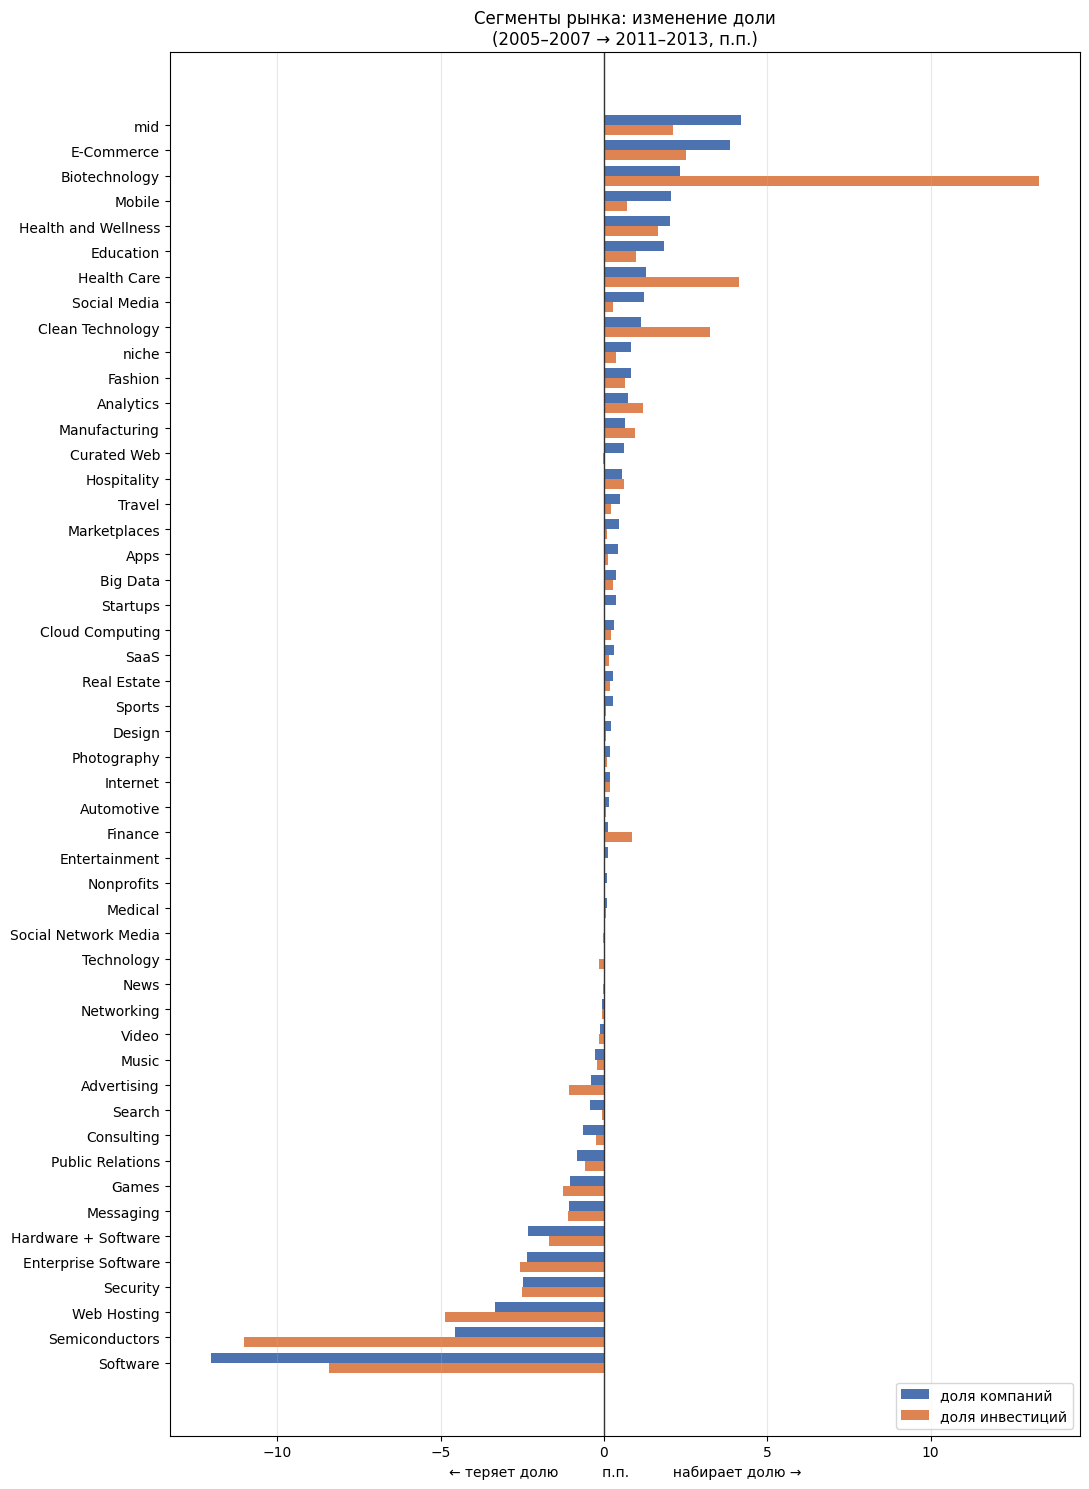

In [24]:
# Сегменты рынка: массовые по отдельности, средние (mid) и нишевые (niche) – как два общих сегмента.
# Смотрим долю массовых сегментов на рынке и как менялся интерес к каждому сегменту
mass = clean_df[clean_df['market_type'] == 'массовый']
seg = clean_df[clean_df['market'] != 'unknown']   # все сегменты, включая mid и niche
companies_by_year = clean_df.groupby('year').size()
money_by_year = clean_df.groupby('year')['funding_total_usd'].sum()

# 1. Доля всех массовых сегментов по годам
mass_share = pd.DataFrame({
    'доля компаний, %': mass.groupby('year').size() / companies_by_year * 100,
    'доля инвестиций, %': mass.groupby('year')['funding_total_usd'].sum() / money_by_year * 100})
display(mass_share.T.round(1))

# 2. Доля каждого сегмента: 2005–2007 против 2011–2013
#    (2014 г. не берём – в нём рынки размечены по-другому, много 'unknown' и новых категорий)
seg_comp = pd.crosstab(seg['market'], seg['year']).div(companies_by_year, axis=1) * 100
seg_inv = seg.pivot_table(index='market', columns='year', values='funding_total_usd',
                           aggfunc='sum').div(money_by_year, axis=1) * 100
early, late = [2005, 2006, 2007], [2011, 2012, 2013]

change = pd.DataFrame({
    'компании 2005–07, %': seg_comp[early].mean(axis=1),
    'компании 2011–13, %': seg_comp[late].mean(axis=1),
    'инвестиции 2005–07, %': seg_inv[early].mean(axis=1),
    'инвестиции 2011–13, %': seg_inv[late].mean(axis=1)})
change['изм. доли компаний, п.п.'] = change['компании 2011–13, %'] - change['компании 2005–07, %']
change['изм. доли инвестиций, п.п.'] = change['инвестиции 2011–13, %'] - change['инвестиции 2005–07, %']
change = change.sort_values('изм. доли компаний, п.п.', ascending=False)
display(change.round(1))

# График: кто набирает долю (вправо), кто теряет (влево)
p = change[::-1]                                       # сверху – наибольший рост
y = np.arange(len(p))
h = 0.4
fig, ax = plt.subplots(figsize=(11, 15))
ax.barh(y + h / 2, p['изм. доли компаний, п.п.'], height=h, color='#4C72B0', label='доля компаний')
ax.barh(y - h / 2, p['изм. доли инвестиций, п.п.'], height=h, color='#DD8452', label='доля инвестиций')
ax.axvline(0, color='#333333', lw=1)
ax.set_yticks(y)
ax.set_yticklabels(p.index)
ax.set(title='Сегменты рынка: изменение доли\n(2005–2007 → 2011–2013, п.п.)',
       xlabel='← теряет долю          п.п.          набирает долю →')
ax.grid(axis='x', alpha=0.3)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()


**Выводы**

**Раунды и объёмы по годам**

- **Компаний и раундов стало намного больше, денег – тоже, но рост медленнее.** К 2013 г. компаний в 11 раз больше, чем в 2005 г. (7,9 тыс. против 0,7 тыс.), раундов – в 13,5 раза (12,9 тыс. против 1,0 тыс.). Объём инвестиций вырос в 4,8 раза: с 5,1 до 24,9 млрд долл.
- **Чеки мельчают.** Средний раунд сократился почти втрое (5,4 → 1,9 млн долл), медиана на компанию – в 6 раз (5,3 → 0,9 млн долл в 2013 г.). На рынок массово пришли стартапы ранних стадий с небольшими посевными раундами.
- **Важно:** данные за 2014 г. неполные (последние месяцы почти не заполнены), поэтому число компаний, раундов и объём за этот год занижены.

**Сегменты рынка**

- На 48 массовых сегментов приходится 87–93% компаний и 93–95% денег в 2005–2011 гг. Падение доли в 2014 г. до 65% компаний и 74% денег – в основном из-за новой разметки рынков (больше `unknown` и новых категорий), поэтому сравниваем 2005–07 и 2011–13 гг.
- **Теряют долю** корпоративное ПО и «железо»: Software (–12 п.п. компаний, –8 п.п. инвестиций), Semiconductors (–4,6 и –11 п.п.), Web Hosting (–3,3 и –4,9 п.п.), Security, Enterprise Software, Hardware + Software (по –2–3 п.п.).
- **Набирают долю** потребительские интернет-сегменты: E-Commerce (+3,9 п.п. компаний, +2,5 п.п. инвестиций), Mobile (+2,1 и +0,7), Health and Wellness (+2,0 и +1,6), Education (+1,8 и +1,0).
- **Biotechnology** растёт по числу компаний (+2,3 п.п.), а его доля в инвестициях выросла более чем вдвое (10,6% → 23,9%) – это крупнейший получатель капитала. Заметно прибавили по деньгам также Health Care (+4,1 п.п.) и Clean Technology (+3,3 п.п.).
- Средние сегменты (`mid`) вместе набирают долю: 4,8% → 9,0% компаний (+4,2 п.п.) и 3,9% → 6,0% инвестиций. Нишевые (`niche`) выросли с 0,3% до 1,1% компаний. Рынок становится разнообразнее: новые компании всё чаще появляются вне крупнейших направлений.

**Итог:** рынок стал массовым и «дешёвым» – компаний и раундов больше, чеки меньше. Интерес смещается от корпоративного ПО и полупроводников к потребительскому интернету и здоровью. Biotechnology стал крупнейшим получателем капитала только к 2011–2013 гг. (23,9% инвестиций), а в 2005–2007 гг. больше получали Software (16,5%) и Semiconductors (12,2%).

Массовых сегментов: 48, из них росли в 2014 году: 10


,"2012, млн $","2013, млн $","2014, млн $","прирост 2014 к 2013, млн $","прирост 2014 к 2013, %",лет роста подряд
market,,,,,,
Manufacturing,522.2,393.9,416.3,22.4,5.7,1
Technology,193.3,120.9,202.0,81.1,67.1,1
Medical,44.0,64.5,175.2,110.8,171.8,5
Internet,28.3,69.7,117.8,48.1,69.0,2
Real Estate,77.3,92.2,115.6,23.4,25.3,3
SaaS,49.7,79.6,92.8,13.2,16.6,3
Big Data,86.4,78.7,79.2,0.5,0.7,1
Design,39.6,61.0,69.0,8.0,13.2,3
Apps,32.6,28.9,66.2,37.4,129.4,1


year,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014
market,,,,,,,,,,
Manufacturing,61.8,164.0,147.7,173.1,422.9,244.3,561.6,522.2,393.9,416.3
Technology,50.7,22.8,180.2,277.7,36.1,312.5,143.2,193.3,120.9,202.0
Medical,11.1,20.2,2.1,28.8,11.6,25.6,28.5,44.0,64.5,175.2
Internet,1.8,0.0,4.5,23.4,38.2,36.7,36.9,28.3,69.7,117.8
Real Estate,0.2,2.1,33.2,46.6,38.8,37.3,20.0,77.3,92.2,115.6
SaaS,5.2,4.8,14.7,27.2,13.5,32.6,32.2,49.7,79.6,92.8
Big Data,0.0,0.0,7.8,2.5,0.6,39.2,60.4,86.4,78.7,79.2
Design,9.3,0.7,10.8,5.9,2.2,17.2,8.9,39.6,61.0,69.0
Apps,0.0,1.3,0.0,4.3,7.2,6.1,18.4,32.6,28.9,66.2


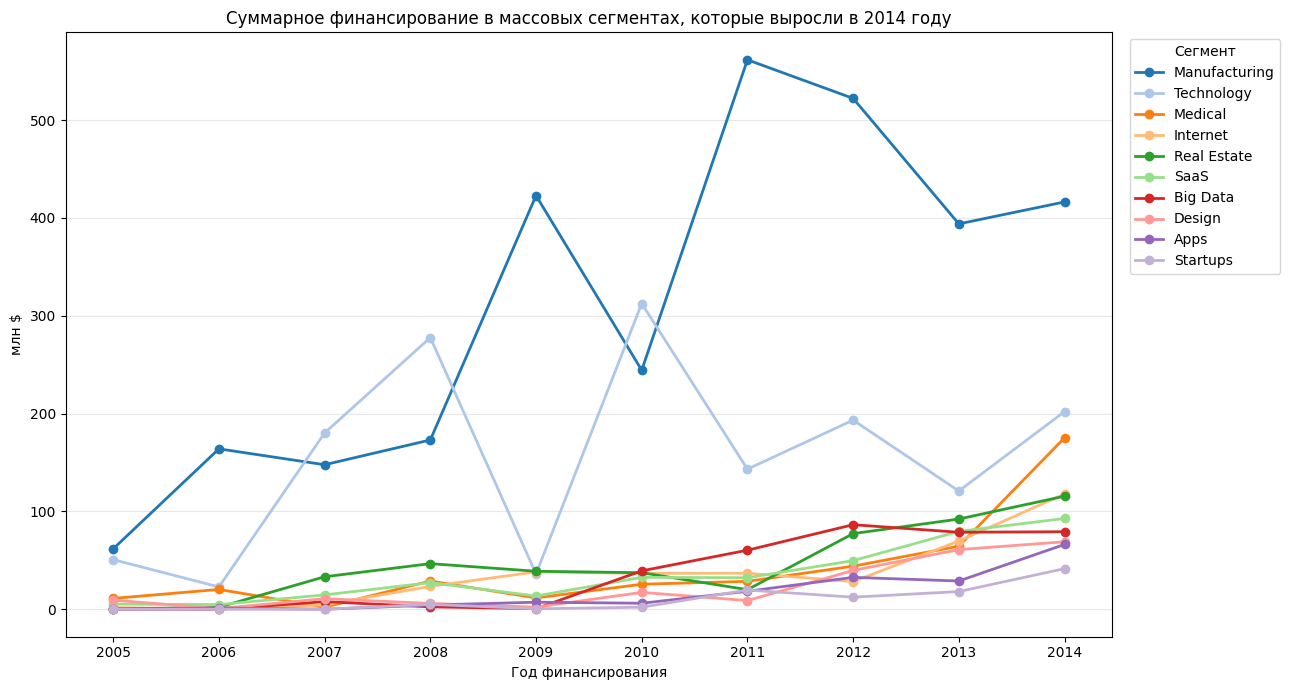

In [25]:
# Сводная таблица: суммарное финансирование по годам и массовым сегментам рынка, млн $
# (средние mid, нишевые niche и unknown не рассматриваем)
mass_df = clean_df[clean_df['market_type'] == 'массовый']
seg_funding = mass_df.pivot_table(index='year', columns='market', values='funding_total_usd',
                                  aggfunc='sum', fill_value=0) / 1e6

# Сегменты, у которых суммарное финансирование в 2014 году выше, чем в 2013
growing = seg_funding.columns[seg_funding.loc[2014] > seg_funding.loc[2013]]
print(f'Массовых сегментов: {seg_funding.shape[1]}, из них росли в 2014 году: {len(growing)}')

growth = pd.DataFrame({
    '2012, млн $': seg_funding.loc[2012, growing],
    '2013, млн $': seg_funding.loc[2013, growing],
    '2014, млн $': seg_funding.loc[2014, growing]})
growth['прирост 2014 к 2013, млн $'] = growth['2014, млн $'] - growth['2013, млн $']
growth['прирост 2014 к 2013, %'] = (growth['2014, млн $'] / growth['2013, млн $'] - 1) * 100
# Сколько лет подряд до 2014 года финансирование сегмента росло
diffs = seg_funding[growing].diff().loc[2006:]
growth['лет роста подряд'] = [int((diffs[c][::-1] > 0).cumprod().sum()) for c in growing]
growth = growth.sort_values('2014, млн $', ascending=False)
display(growth.round(1))

# Сводная таблица по отобранным сегментам (с 2005 года – раньше данных слишком мало)
display(seg_funding.loc[2005:, growth.index].T.round(1))

# График: динамика суммарного финансирования в отобранных сегментах
plot_data = seg_funding.loc[2005:, growth.index]
seg_colors = plt.cm.tab20.colors
fig, ax = plt.subplots(figsize=(13, 7))
for i, col in enumerate(plot_data.columns):
    ax.plot(plot_data.index, plot_data[col], marker='o', lw=2, color=seg_colors[i % 20], label=col)
ax.set_xticks(list(plot_data.index))
ax.set(title='Суммарное финансирование в массовых сегментах, которые выросли в 2014 году',
       xlabel='Год финансирования', ylabel='млн $')
ax.legend(title='Сегмент', bbox_to_anchor=(1.01, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Массовые сегменты, которые росли в 2014 году**

Классификация пересчитана на очищенных данных: массовых сегментов 48, и суммарное финансирование в 2014 году выросло только у 10 из них. Данные за 2014 год неполные, поэтому рост в этих сегментах – сильный сигнал: они прибавили даже без последних месяцев года. График построен с 2005 года: раньше данных слишком мало.

- **Самый быстрый и уверенный рост – Medical:** финансирование растёт 5 лет подряд (12 млн долл в 2009 г. → 64 млн в 2013 г. → 175 млн в 2014 г., +172% за последний год).
- **Уверенный рост три года подряд:** Real Estate (20 → 77 → 92 → 116 млн долл) и SaaS (32 → 50 → 80 → 93 млн долл). Рост не самый резкий, но устойчивый. Три года подряд растёт также Design, но объёмы у него меньше.
- **Быстрый рост два года подряд:** Internet (28 → 70 → 118 млн долл) и Startups (12 → 18 → 42 млн долл, сегмент маленький).
- **Резкий скачок только в 2014 году:** Apps (+129%) и Technology (+67%, но сегмент сильно колеблется от года к году). Рост быстрый, но один год – ещё не тенденция.
- **Крупные, но неустойчивые:** Manufacturing – самый большой из отобранных сегментов (416 млн долл), но прирост всего 6%, и он ниже пика 2011 года. Big Data после быстрого роста 2010–2012 гг. вышла на плато (+0,7%).
- Medical Devices, Media и Financial Services, которые на неочищенной базе были в этом списке, теперь относятся к средним сегментам (меньше 120 компаний) и в отбор не входят.

**Вывод:** наиболее быстрый и уверенный рост показывают Medical, Real Estate, SaaS и Internet – у них финансирование растёт несколько лет подряд. Все отобранные сегменты невелики: ни один из крупнейших (Software, Biotechnology, Mobile, E-Commerce) в 2014 году не вырос.

<a id="returns"></a>
### Доля возврата средств по типам финансирования и её устойчивость

**Доля возврата** – сколько процентов от вложенных за год денег вернулось инвесторам в том же году: возвраты `returns_df` / инвестиции `clean_df` × 100%. Возвраты и инвестиции берём за одни и те же годы – 2005–2013; 2014 год неполный (инвестиции занижены), его показываем отдельной колонкой для справки и в итоговые показатели не включаем.

**Устойчивость** – насколько сильно доля меняется от года к году. Меряем коэффициентом вариации CV = std / mean: до 0,5 – устойчивая, 0,5–1 – умеренная, больше 1 – неустойчивая.

Заменено на пропуски: 22 значений из 195
equity_crowdfunding     2
convertible_note        4
private_equity          2
post_ipo_equity         4
secondary_market       10


year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014
venture,0.16,0.09,0.61,0.63,0.79,0.54,0.34,0.30,0.19,0.17,0.20,0.25,0.31,0.35,0.75
debt_financing,0.62,0.77,0.22,1.04,0.44,0.34,0.80,0.60,0.93,0.34,0.44,0.50,0.49,0.48,1.14
private_equity,0.00,0.00,0.09,NaN,NaN,0.48,0.47,0.58,0.68,0.75,0.65,0.72,0.92,0.58,0.97
seed,1.00,0.70,0.63,0.51,0.55,0.67,0.93,0.37,0.30,0.56,0.53,0.27,0.19,0.15,0.28
angel,0.27,1.18,1.14,0.61,0.83,0.51,0.67,0.82,0.41,0.62,0.64,0.44,0.50,0.54,1.07


,2009,2013,изменение 2009 → 2013,лет роста из 4
venture,0.17,0.35,0.18,4
debt_financing,0.34,0.48,0.14,2
private_equity,0.75,0.58,-0.17,2
seed,0.56,0.15,-0.42,0
angel,0.62,0.54,-0.07,3


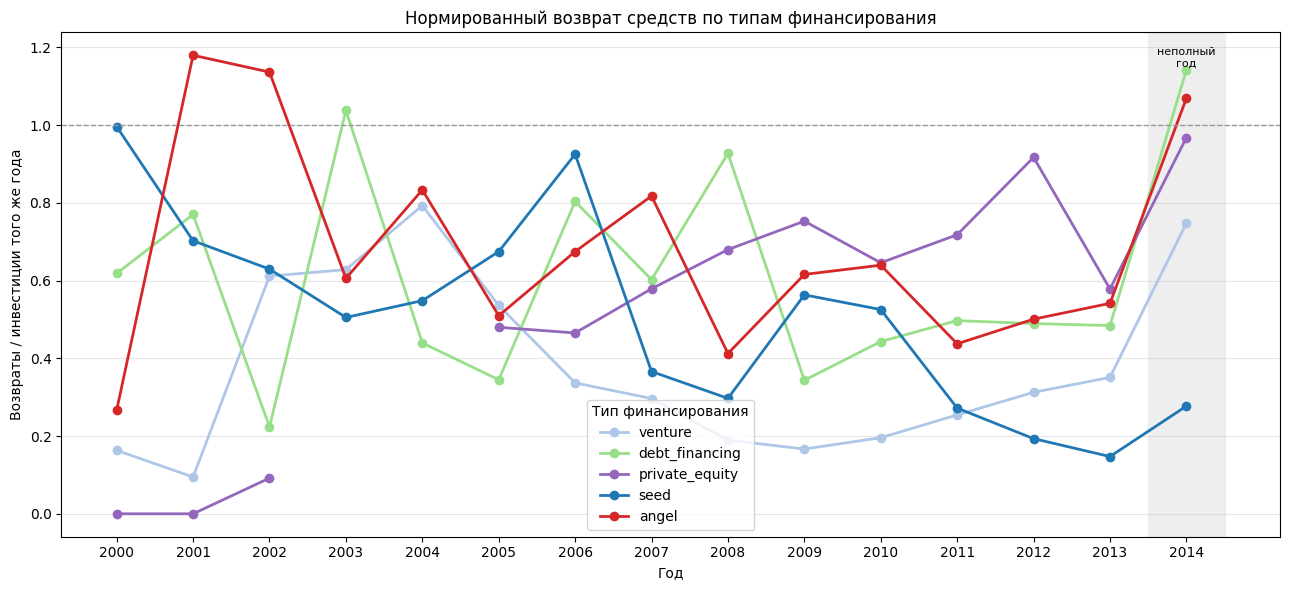

In [26]:
# Нормированный возврат: какую долю возвращённые средства составляют от предоставленных,
# для каждого года и каждого типа финансирования (returns_df – в млн $, инвестиции тоже переводим в млн $)
invested = clean_df.groupby('year')[fund_types].sum() / 1e6
invested = invested.reindex(returns_df.index).fillna(0)

# К знаменателю добавляем малое число, чтобы не делить на ноль
returns_norm = returns_df[fund_types] / (invested + 1e-60)

# Неадекватные выбросы заменяем на пропуски. Они возникают, когда инвестиций типа в этом году
# в данных нет или почти нет: деление даёт значения порядка 1e58–1e61. Порог – возврат больше 10 вложений
OUTLIER_LIMIT = 10
is_anomaly = returns_norm > OUTLIER_LIMIT
print('Заменено на пропуски:', int(is_anomaly.sum().sum()), 'значений из', returns_norm.size)
print(is_anomaly.sum()[is_anomaly.sum() > 0].to_string())
returns_norm = returns_norm.mask(is_anomaly)

main_types = ['venture', 'debt_financing', 'private_equity', 'seed', 'angel']
display(returns_norm[main_types].T.round(2))

# Устойчивость роста в 2009–2013 гг. (2014 г. не берём – данные неполные)
period = returns_norm.loc[2009:2013, main_types]
trend = pd.DataFrame({
    '2009': period.loc[2009],
    '2013': period.loc[2013],
    'изменение 2009 → 2013': period.loc[2013] - period.loc[2009],
    'лет роста из 4': (period.diff().dropna() > 0).sum()})
display(trend.round(2))

# График: нормированный возврат по годам для основных типов финансирования
fig, ax = plt.subplots(figsize=(13, 6))
for t in main_types:
    ax.plot(returns_norm.index, returns_norm[t], marker='o', lw=2, color=fund_colors[t], label=t)
ax.axhline(1, color='#999999', lw=1, ls='--')
ax.axvspan(2013.5, 2014.5, color='#EEEEEE', zorder=0)
ax.text(2014, ax.get_ylim()[1] * 0.97, 'неполный\nгод', ha='center', va='top', fontsize=8)
ax.set_xticks(list(returns_norm.index))
ax.set(title='Нормированный возврат средств по типам финансирования',
       xlabel='Год', ylabel='Возвраты / инвестиции того же года')
ax.legend(title='Тип финансирования')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Годовая динамика нормированного возврата**

Нормированный возврат – это возвраты за год, делённые на инвестиции того же года и того же типа (2000–2014 гг.). 22 значения из 195 заменены на пропуски: в эти годы инвестиций типа в данных нет, и деление даёт неадекватные числа порядка 1e58–1e61. Среди пяти основных типов это коснулось только private equity (2003 и 2004 гг.).

**Почему смотрим на окно 2009–2013.** Это последние пять полных лет перед моментом принятия решения (2014 год неполный). Но окно начинается в точке минимума: после 2004–2005 гг. возврат по venture падал (0,79 в 2004 г., 0,54 в 2005 г. → 0,17 в 2009 г.), поэтому рост внутри окна – это восстановление после спада, а не выход на новые максимумы.

- **Venture** растёт каждый год с 2009 по 2013: 0,17 → 0,20 → 0,25 → 0,31 → 0,35, то есть вдвое за четыре года. При этом уровень 2013 г. (0,35) всё ещё ниже уровня 2005 г. (0,54) – это восстановление, а не рост выше обычного уровня.
- **Debt financing** рос в 2009–2011 гг. (0,34 → 0,50), а в 2012–2013 гг. держится на том же уровне (0,49–0,48): рост остановился, показатель вышел на плато.
- **Angel** после падения в 2011 г. растёт (0,44 → 0,50 → 0,54), но уровень 2009–2010 гг. (0,62–0,64) не вернулся.
- **Private equity** держится высоко (0,58–0,92), но без тенденции: рост и падение чередуются.
- **Seed** устойчиво снижается: 0,56 в 2009 г. → 0,15 в 2013 г. Посевных инвестиций становится всё больше, а возвраты за ними не успевают.

**Оговорки.** Всплеск 2014 года у всех типов – артефакт: данные об инвестициях за этот год неполные, знаменатель занижен. До 2005 года значения скачут из-за малого числа компаний. Абсолютный уровень завышен, потому что возвраты от аномалий не очищались, а инвестиции взяты из очищенного `clean_df`.

,"доля возврата, %","мин. по годам, %","макс. по годам, %",CV,"2005–09, %","2010–13, %","2014 (неполный), %",устойчивость
post_ipo_equity,85.9,54.4,234.1,0.6,234.3,70.8,25.3,умеренная
private_equity,68.8,46.5,91.7,0.2,67.3,69.0,96.8,устойчивая
angel,54.6,41.2,81.8,0.2,59.9,51.9,106.9,устойчивая
debt_financing,49.2,34.4,92.7,0.4,52.6,48.0,114.2,устойчивая
post_ipo_debt,42.9,26.2,98.1,0.6,NaN,42.9,23.1,умеренная
venture,27.0,16.7,53.6,0.4,26.2,27.8,74.8,устойчивая
undisclosed,26.7,15.8,107.2,0.7,43.8,20.8,45.7,умеренная
seed,24.1,14.7,92.5,0.6,46.2,21.2,27.7,умеренная
secondary_market,8.6,0.6,19.8,1.5,6.9,11.1,21.2,неустойчивая
convertible_note,6.0,4.5,22.8,0.7,9.4,5.1,6.7,умеренная


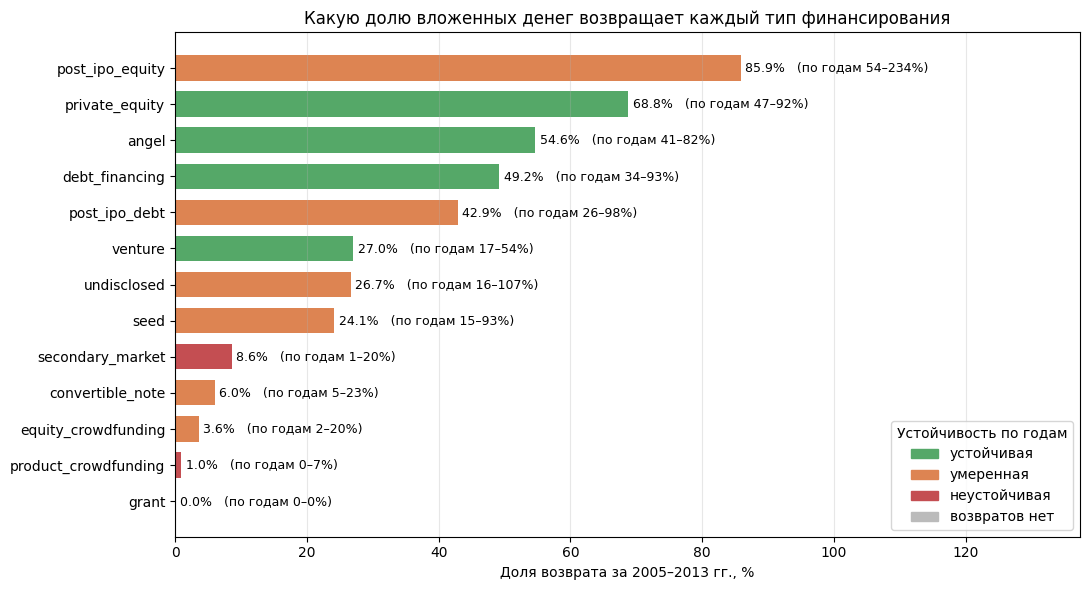

In [27]:
# Доля возврата = возвраты / инвестиции того же года, %
# (returns_df – в млн $, инвестиции из clean_df тоже переводим в млн $)
# Период 2005–2013: 2014 год неполный (знаменатель занижен), поэтому в итоговые показатели его не берём.
# Инвестиции в знаменателе берём за те же годы, что и возвраты в числителе
ret_years = list(range(2005, 2014))
ret = returns_df.loc[ret_years, fund_types]
inv_all = clean_df.groupby('year')[fund_types].sum() / 1e6
inv = inv_all.loc[ret_years]
assert list(ret.index) == list(inv.index)  # периоды числителя и знаменателя совпадают

share = ret / inv * 100                        # доля возврата по годам
share = share.replace(np.inf, np.nan)          # годы без инвестиций не учитываем

# Итоговая таблица: уровень возврата и его устойчивость
result = pd.DataFrame({
    'доля возврата, %': ret.sum() / inv.sum() * 100,          # за весь период
    'мин. по годам, %': share.min(),
    'макс. по годам, %': share.max(),
    'CV': share.std() / share.mean(),                          # разброс относительно среднего
    '2005–09, %': ret.loc[:2009].sum() / inv.loc[:2009].sum() * 100,
    '2010–13, %': ret.loc[2010:].sum() / inv.loc[2010:].sum() * 100,
    '2014 (неполный), %': (returns_df.loc[2014, fund_types] / inv_all.loc[2014] * 100).replace(np.inf, np.nan)})

# Устойчивость по CV: до 0,5 – устойчивая, 0,5–1 – умеренная, больше 1 – неустойчивая
result['устойчивость'] = 'неустойчивая'
result.loc[result['CV'] <= 1, 'устойчивость'] = 'умеренная'
result.loc[result['CV'] <= 0.5, 'устойчивость'] = 'устойчивая'
result.loc[ret.sum() == 0, 'устойчивость'] = 'возвратов нет'

result = result.sort_values('доля возврата, %', ascending=False)
display(result.round(1))

# График: доля возврата за период, цвет – устойчивость, справа – разброс по годам
colors = {'устойчивая': '#55A868', 'умеренная': '#DD8452',
          'неустойчивая': '#C44E52', 'возвратов нет': '#BBBBBB'}
p = result[::-1]                               # сверху – наибольшая доля
y = np.arange(len(p))

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(y, p['доля возврата, %'], color=[colors[s] for s in p['устойчивость']], height=0.7)
for i in range(len(p)):
    ax.text(p['доля возврата, %'].iloc[i] + 0.7, y[i],
            '{:.1f}%   (по годам {:.0f}–{:.0f}%)'.format(p['доля возврата, %'].iloc[i],
                                                         p['мин. по годам, %'].iloc[i],
                                                         p['макс. по годам, %'].iloc[i]),
            va='center', fontsize=9)
ax.set_yticks(y)
ax.set_yticklabels(p.index)
ax.set_xlim(0, p['доля возврата, %'].max() * 1.6)
ax.set(xlabel='Доля возврата за 2005–2013 гг., %',
       title='Какую долю вложенных денег возвращает каждый тип финансирования')
ax.grid(axis='x', alpha=0.3)

# Легенда цветов (простые прямоугольники работают во всех версиях matplotlib)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
ax.legend(handles, list(colors.keys()), title='Устойчивость по годам', loc='lower right')
plt.tight_layout()
plt.show()


**Выводы**

Доля возврата посчитана за 2005–2013 гг.: возвраты и инвестиции берутся за одни и те же годы, неполный 2014 год в итоговые показатели и CV не входит.

| Группа | Типы финансирования | Доля возврата | Устойчивость |
|---|---|---|---|
| Высокий и стабильный возврат | private equity, angel, debt financing | 49–69% | устойчивая (CV 0,2–0,4) |
| Средний возврат | post-IPO debt, venture, undisclosed, seed | 24–43% | от устойчивой до умеренной (CV 0,4–0,7) |
| Низкий возврат | secondary market, convertible note, краудфандинг | 1–9% | умеренная или неустойчивая |
| Без возврата | grant | 0% | – |
| Оценка ненадёжна | post-IPO equity | 86% | умеренная (CV 0,6), но в 2005–09 гг. доля 234% |

- **Private equity, angel и debt financing** – самые надёжные: высокая доля возврата и небольшой разброс по годам (CV 0,2–0,4); в 2005–09 и 2010–13 гг. доля меняется мало.
- **Seed** – главное изменение: 24,1% за период, и доля сильно снижается – 46,2% в 2005–09 гг. → 21,2% в 2010–13 гг. Посевных инвестиций стало намного больше, а возвраты по ним растут медленнее.
- **Venture** – 27,0% за период, без заметного роста: 26,2% в 2005–09 гг. и 27,8% в 2010–13 гг. – разница в пределах колебаний. Зато разброс по годам небольшой (CV 0,39), то есть возврат по venture невысокий, но предсказуемый.
- **Post-IPO equity** – 86%, но оценка ненадёжна: в 2005–09 гг. доля превышает 200%, потому что инвестиций этого типа в очищенных данных очень мало.
- **Низкая группа** – малые объёмы, поэтому один-два возврата резко меняют долю; оценки по ним ненадёжны.

**Важно:** это отношение потоков денег одного года, а не доходность конкретных вложений (ROI). Возвраты в `returns_df` от аномалий не очищались, а инвестиции взяты из `clean_df`, откуда исключены компании с аномально крупным финансированием. Поэтому абсолютный уровень долей завышен (в отдельные годы он превышает 100%), и надёжнее сравнивать типы между собой, а не смотреть на сами проценты.

<a id="outcomes"></a>
### Дополнительная проверка: исходы компаний по сегментам

Чтобы рекомендации по сегментам опирались не только на поток денег, смотрим, чем закончились компании когорт 2005–2009 гг. (у них было 5+ лет): доля выходов (acquired / ipo) и доля закрытий.

,компаний,"выход (acquired + ipo), %","закрылись, %","медиана на компанию, млн $","изм. доли компаний 2005–07 → 2011–13, п.п.",достаточно данных
market,,,,,,
Enterprise Software,399,30.3,8.3,7.0,-2.4,True
Cloud Computing,20,30.0,20.0,3.5,0.3,False
Web Hosting,202,29.7,12.9,8.0,-3.3,True
Security,198,26.8,9.1,6.5,-2.5,True
Nonprofits,15,26.7,13.3,2.4,0.1,False
Networking,30,26.7,26.7,2.1,-0.0,True
Public Relations,55,25.5,36.4,3.0,-0.8,True
Video,46,23.9,19.6,2.0,-0.1,True
Semiconductors,287,23.7,11.5,14.4,-4.6,True


Сегменты с когортой меньше 30 компаний (в график и выводы не берём): Cloud Computing (20), Nonprofits (15), Medical (9), Sports (25), Entertainment (15), Marketplaces (7), Apps (8), Automotive (23), niche (27), Fashion (17), Big Data (7), Startups (8), Design (14)
Медиана доли выходов по сегментам с достаточной когортой: 17.2%


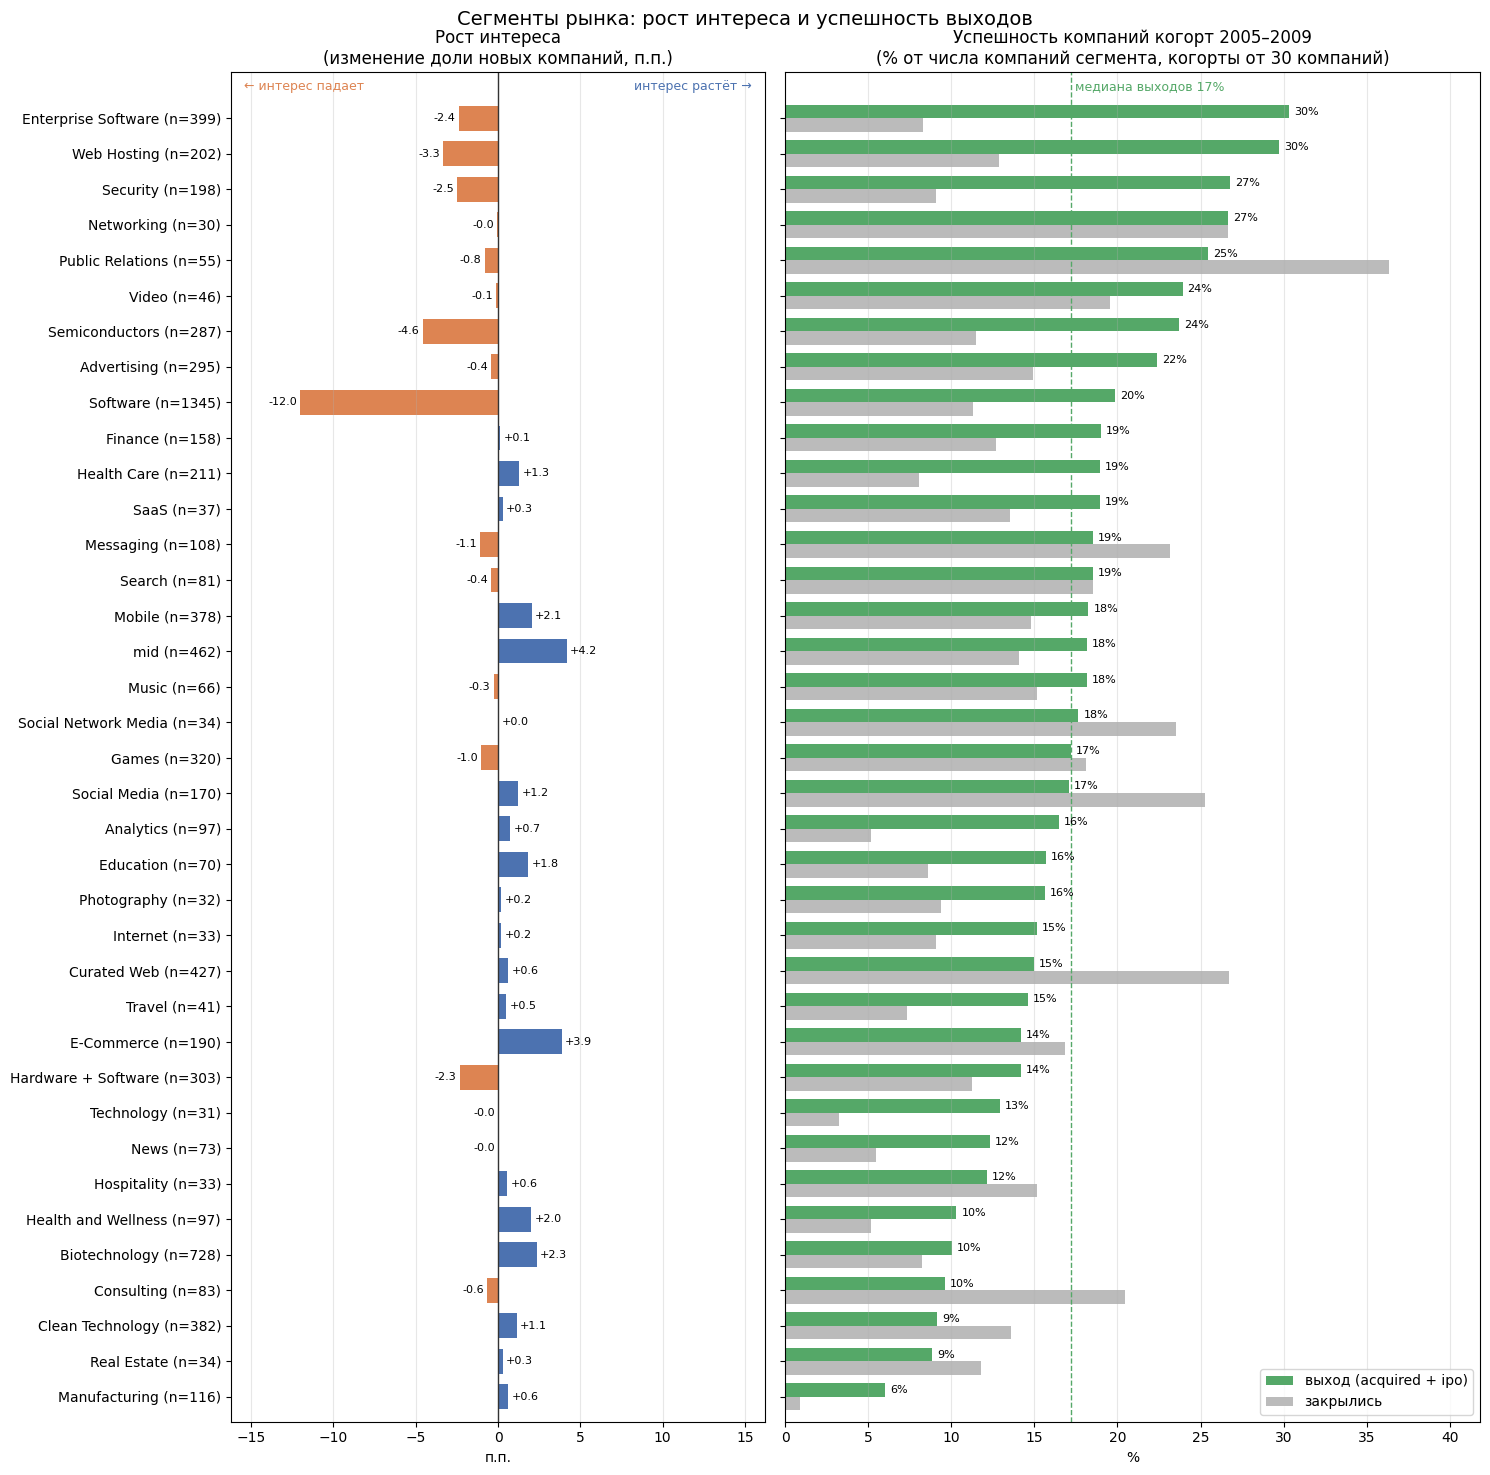

In [28]:
# Дополнительная проверка для рекомендаций: исходы компаний по сегментам
# (массовые по отдельности, средние – mid, нишевые – niche).
# Берём когорты 2005–2009 – у них было 5+ лет, чтобы прийти к выходу (acquired / ipo) или закрыться
old = clean_df[(clean_df['market'] != 'unknown') & clean_df['year'].between(2005, 2009)]
g = old.groupby('market')
outcomes = pd.DataFrame({
    'компаний': g.size(),
    'выход (acquired + ipo), %': g['status'].apply(lambda s: s.isin(['acquired', 'ipo']).mean() * 100),
    'закрылись, %': g['status'].apply(lambda s: (s == 'closed').mean() * 100),
    'медиана на компанию, млн $': g['funding_total_usd'].median() / 1e6,
    'изм. доли компаний 2005–07 → 2011–13, п.п.': change['изм. доли компаний, п.п.'],
}).sort_values('выход (acquired + ipo), %', ascending=False)
# Доли по когортам из нескольких компаний прыгают от одного события, поэтому выводы делаем
# только по сегментам, где в когортах 2005–2009 не меньше MIN_COHORT компаний
MIN_COHORT = 30
outcomes['достаточно данных'] = outcomes['компаний'] >= MIN_COHORT
display(outcomes.round(1))
small = outcomes[~outcomes['достаточно данных']]
print(f'Сегменты с когортой меньше {MIN_COHORT} компаний (в график и выводы не берём):',
      ', '.join(f'{m} ({n})' for m, n in small['компаний'].items()))
reliable = outcomes[outcomes['достаточно данных']]
print('Медиана доли выходов по сегментам с достаточной когортой: {:.1f}%'.format(reliable['выход (acquired + ipo), %'].median()))

# График: две панели с общим списком сегментов (сверху – самые успешные по выходам)
#   слева  – рост интереса: как изменилась доля сегмента среди новых компаний;
#   справа – результат: доля выходов (acquired / ipo) и доля закрытий у когорт 2005–2009.
plot_df = reliable.sort_values('выход (acquired + ipo), %')  # по возрастанию – лучшие окажутся сверху
growth = plot_df['изм. доли компаний 2005–07 → 2011–13, п.п.']
exits = plot_df['выход (acquired + ipo), %']
closed = plot_df['закрылись, %']
y = np.arange(len(plot_df))
exit_median = exits.median()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 15), sharey=True,
                               gridspec_kw={'width_ratios': [1, 1.3]})

# Слева: рост (синий) / снижение (оранжевый) доли новых компаний
ax1.barh(y, growth, color=np.where(growth >= 0, '#4C72B0', '#DD8452'), height=0.7)
for i in range(len(y)):
    v = growth.iloc[i]
    ax1.text(v + (0.2 if v >= 0 else -0.2), y[i], '{:+.1f}'.format(v),
             ha='left' if v >= 0 else 'right', va='center', fontsize=8)
ax1.axvline(0, color='#333333', lw=1)
lim = abs(growth).max() * 1.35
ax1.set_xlim(-lim, lim)
ax1.set(title='Рост интереса\n(изменение доли новых компаний, п.п.)', xlabel='п.п.')
ax1.text(-lim * 0.95, len(y) - 0.3, '← интерес падает', color='#DD8452', fontsize=9, va='bottom')
ax1.text(lim * 0.95, len(y) - 0.3, 'интерес растёт →', color='#4C72B0', fontsize=9, va='bottom', ha='right')

# Справа: доля выходов и доля закрытий
h = 0.38
ax2.barh(y + h / 2, exits, height=h, color='#55A868', label='выход (acquired + ipo)')
ax2.barh(y - h / 2, closed, height=h, color='#BBBBBB', label='закрылись')
for i in range(len(y)):
    ax2.text(exits.iloc[i] + 0.3, y[i] + h / 2, '{:.0f}%'.format(exits.iloc[i]), va='center', fontsize=8)
ax2.axvline(exit_median, color='#55A868', lw=1, ls='--')
ax2.text(exit_median, len(y) - 0.3, ' медиана выходов {:.0f}%'.format(exit_median),
         color='#55A868', fontsize=9, va='bottom')
ax2.set_xlim(0, max(exits.max(), closed.max()) * 1.15)
ax2.set(title=f'Успешность компаний когорт 2005–2009\n(% от числа компаний сегмента, когорты от {MIN_COHORT} компаний)', xlabel='%')
ax2.legend(loc='lower right')

ax1.set_yticks(y)
ax1.set_yticklabels([f'{m} (n={n})' for m, n in plot_df['компаний'].items()])  # размер когорты рядом с названием
ax1.set_ylim(-0.7, len(y) + 0.3)
for ax in (ax1, ax2):
    ax.grid(axis='x', alpha=0.3)
plt.suptitle('Сегменты рынка: рост интереса и успешность выходов', fontsize=14)
plt.tight_layout()
plt.show()


**Выводы по исходам компаний**

- Выводы делаем только по сегментам, где в когортах 2005–2009 не меньше 30 компаний: у малых сегментов (Medical – 9 компаний, Big Data – 7, Design – 14 и др.) доля выходов меняется от одного события.
- Самая высокая доля выходов (acquired + ipo) – у B2B-сегментов: Enterprise Software (30,3%), Web Hosting (29,7%), Security (26,8%). При этом все три теряют долю среди новых компаний. Медиана доли выходов по сегментам – 17,2%.
- У сегментов здоровья картина разная: Health Care – 19,0% выходов (выше медианы), а Biotechnology и Health and Wellness – около 10% при низкой доле закрытий (5–8%). Это сегменты с долгим циклом, где за 5 лет компании чаще продолжают работать, чем выходят.
- У растущих сегментов SaaS (18,9%) и Internet (15,2%) доля выходов около медианы, у Real Estate – ниже (8,8%); когорты у них небольшие (33–37 компаний).

Рост интереса инвесторов и успешность выходов не совпадают: это учитываем в итоговой рекомендации.

### Размер чеков в сегментах для рекомендации

Чтобы сравнить размер чеков в рекомендуемых сегментах, считаем квартили `funding_total_usd` на очищенных данных `clean_df`.

In [29]:
# Квартили суммы финансирования на компанию в сегментах, которые попадают в рекомендацию
rec_segments = ['Health Care', 'Medical', 'SaaS', 'Real Estate']
rec = clean_df[clean_df['market'].isin(rec_segments)].groupby('market')['funding_total_usd']
checks = pd.DataFrame({
    'компаний': rec.size(),
    'Q1, млн $': rec.quantile(0.25) / 1e6,
    'медиана, млн $': rec.median() / 1e6,
    'Q3, млн $': rec.quantile(0.75) / 1e6}).reindex(rec_segments)
display(checks.round(2))

,компаний,"Q1, млн $","медиана, млн $","Q3, млн $"
market,,,,
Health Care,1057,1.00,4.71,16.98
Medical,130,0.11,0.90,4.40
SaaS,228,0.20,0.74,2.00
Real Estate,230,0.15,0.68,2.74


<a id="conclusion"></a>
## Итоговые выводы и рекомендации

### Рекомендация заказчику на 2015 год

**Отрасль – здравоохранение: растущий сегмент Medical и более крупный Health Care.**

- Medical – единственный массовый сегмент, где суммарное финансирование растёт пять лет подряд: с 12 млн долл в 2009 г. до 64 млн в 2013 г. и 175 млн долл в 2014 г. (+172%).
- Это часть общего сдвига капитала в здоровье: доля Biotechnology в инвестициях выросла с 10,6% до 23,9% (2005–07 → 2011–13), Health Care прибавил 4,1 п.п. инвестиций, Health and Wellness – 2,0 п.п. компаний.
- Рост Medical получен даже на неполных данных за 2014 год, когда финансирование выросло только у 10 массовых сегментов из 48, а крупнейшие (Software, Biotechnology, Mobile, E-Commerce) не выросли.
- Medical – небольшой сегмент (151 компания), а в когортах 2005–2009 у него всего 9 компаний, так что успешность выходов по нему проверить нельзя. Поэтому вложения в Medical стоит дополнить сегментом Health Care: он крупный (1 185 компаний), его доля в инвестициях растёт, а доля выходов у когорт 2005–2009 – 19,0% при медиане 17,2% по сегментам с достаточной когортой.
- **Запасной вариант – SaaS и Real Estate:** финансирование растёт три года подряд. Это сигнал устойчивого интереса инвесторов, а не более быстрого выхода: время до выхода в проекте не считалось, а доля выходов у когорт 2005–2009 у SaaS около медианы (18,9%, 37 компаний), у Real Estate ниже (8,8%, 34 компании). Самые высокие доли выходов (27–30%) дают Enterprise Software, Web Hosting и Security, но эти сегменты теряют долю рынка.

**Тип финансирования – venture.**

- Это основной канал рынка: его получали 53% компаний, на него приходится 80% объёма инвестиций и 74% всех возвратов.
- Доля возврата по venture невысокая, но предсказуемая: 27,0% за 2005–2013 гг. при небольшом разбросе по годам (CV 0,39), без заметного роста (26,2% в 2005–09 гг. и 27,8% в 2010–13 гг.). Нормированный возврат с 2009 по 2013 г. вырос с 0,17 до 0,35 – это восстановление после спада, уровень 2005 г. (0,54) ещё не достигнут.
- Venture подходит медицинским сегментам по размеру чеков: у Health Care три четверти компаний привлекают до 17,0 млн долл (медиана 4,7 млн), у Medical – до 4,4 млн долл (медиана 0,9 млн), см. таблицу квартилей выше; посевных раундов (медиана 0,3 млн долл) для этого недостаточно.
- Debt financing можно добавить как более стабильную часть: доля возврата 49% при CV 0,36, но рост остановился. Seed как основу портфеля не рекомендуем: это самый массовый вход после venture (37% компаний), но доля возврата упала с 46,2% в 2005–09 гг. до 21,2% в 2010–13 гг.

### Какие шаги выполнены

1. **Загрузка и предобработка.** Загрузили `cb_investments` и `cb_returns`, сделали `year` индексом таблицы возвратов. Проверили полные дубликаты – это 4 855 копий пустых строк, после очистки дубликатов нет. Удалили 4 856 пустых строк и строку без названия, а также 8 531 компанию без информации о финансировании (прочерк в общей сумме и нули по всем типам). Осталось 40 906 компаний (75,3% исходных строк). Привели даты и суммы к нужным типам, заполнили пропуски в `mid_funding_at` серединой интервала между первым и последним раундом.
2. **Инжиниринг признаков.** Разделили компании на три группы по сроку финансирования. Выделили массовые (48), средние (57) и нишевые (289) сегменты рынка; средние и нишевые объединили в `mid` и `niche`.
3. **Работа с выбросами.** Пометили аномальное финансирование методом IQR отдельно в каждом сегменте (для `unknown` – общая граница по датасету), 4 983 компании, и исключили их. Проверили данные за 2014 год – они неполные. Оставили годы с 50 и более раундами: 2000–2014. В итоговом датасете 35 847 компаний.
4. **Анализ.** Сравнили типы финансирования по объёму и популярности, посмотрели динамику размера раунда и числа раундов, динамику финансирования по массовым сегментам, долю возврата по типам финансирования и исходы компаний по сегментам.

### Какие выводы удалось сделать

- **Деньги сконцентрированы.** Больше половины компаний (58,9%) получили финансирование один раз, а компании, которые финансируются дольше года (30,0%), собрали 61,9% всего объёма.
- **Рынок стал массовым и дешёвым.** Число раундов выросло с 1,0 тыс. в 2005 г. до 12,9 тыс. в 2013 г., а типичный раунд уменьшился в 8 раз: с 4,5 млн долл в 2005 г. (максимум) до 0,57 млн долл.
- **Venture – главный тип финансирования** и по числу компаний, и по деньгам. Seed и angel используются часто, но дают мало денег; private equity и post-IPO – редкие, но крупные.
- **Интерес смещается.** Доля корпоративного ПО и «железа» падает (Software – с 22,6% до 10,6% компаний, Semiconductors – с 5,0% до 0,5%), растут потребительские сегменты (E-Commerce, Mobile, Health and Wellness, Education) и здоровье.
- **Возврат.** Private equity, angel и debt financing дают самую высокую и стабильную долю возврата; у venture доля возврата стабильна, но не растёт; у seed она заметно снижается.

### Насколько выводы согласуются

**Согласуются:**

- Рост числа раундов, уменьшение типичного раунда и преобладание компаний с одним раундом описывают одну картину – приход множества стартапов ранних стадий.
- Падение доли возврата по seed объясняется тем же: посевных инвестиций стало намного больше, а возвраты за ними не успевают.
- Venture лидирует по объёму и популярности и даёт предсказуемый, хотя и невысокий возврат.

**Вызывают сомнения:**

- **Рост и выходы расходятся.** Лучшие выходы – у сегментов, которые теряют долю рынка (Enterprise Software, Web Hosting, Security), а у крупных сегментов здоровья доля выходов низкая: Biotechnology и Health and Wellness – около 10%. Рекомендация по здравоохранению опирается на рост финансирования, а не на подтверждённые выходы, и требует длинного горизонта – 5 и более лет.
- **Растущие сегменты малы.** У Medical 175 млн долл за 2014 год – несколько крупных сделок могут заметно сдвинуть динамику; по выходам у него слишком маленькая когорта.
- **Состав сегментов чувствителен к базе.** После удаления компаний без финансирования Medical Devices, Media и Financial Services перестали быть массовыми и выпали из отбора – выводы по сегментам рядом с порогом в 120 компаний неустойчивы.
- **2014 год неполный.** Последние месяцы почти не заполнены, поэтому сравнение 2014 года с 2013 занижает рост и могло исключить из отбора сегменты, которые на самом деле выросли.
- **Нормированный возврат – не доходность.** Это отношение потоков одного года, а не возврат на конкретные вложения. Возвраты от аномалий не очищались, а инвестиции очищены, поэтому уровень показателя завышен и в отдельные годы превышает 1; надёжнее смотреть на динамику и сравнение типов.
- **Сумма привязана к одному году.** `funding_total_usd` – это все деньги компании за её историю, а относим мы их к году среднего раунда.
- **Пропуски.** У части компаний не указан рынок (`unknown`) – в 2014 году таких особенно много.
- **Статус компании** (acquired, ipo) не показывает, была ли сделка выгодной для инвестора.